# Pós-Processamento, Auditoria e Visualização dos Artefatos (Padrão Jubiaba & VU13P KKT)
## Análise Estatística, Preços de Sombra ($\mu_j$) e Consumo na FPGA Virtex UltraScale+ VU13P para a Topologia `v2` (25 Anéis)

Este notebook atua como o equivalente ao `Results_CNN_L0Ringer.py` do `codeTCC`, operando de forma **100% desacoplada do treinamento**. Ele lê diretamente os artefatos estruturados no padrão **Jubiaba**:

```text
results/<dataset_prefix>/<model_name>/iet{iet}/ieta{ieta}/v{version}/
├── saved_models/  # model_v{V}_f{F}_r{R}.keras, best_model.keras, best_model.onnx
├── plots/         # Gráficos em alta resolução (300 DPI), incluindo kkt_primal_dual_evolution.png
├── history/       # training_history.csv, history.json
├── metadata/      # training_metadata_v{V}.pkl/.json, cross_validation_results.csv, reproducibility_metadata.json, kkt_allocation_results.json
└── evaluation/    # holdout_test_set.npz, holdout_predictions.npz
```


In [1]:
import os
os.environ["TF_USE_LEGACY_KERAS"] = "1"
import sys
import json
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

repo_root = os.path.abspath(os.path.join(os.getcwd(), '..'))
if not os.path.exists(os.path.join(repo_root, 'src')):
    repo_root = os.path.abspath(os.getcwd())
if repo_root not in sys.path:
    sys.path.insert(0, repo_root)

# Seleção do Experimento a Inspecionar
EXPORT_DIR = os.path.join(repo_root, "results")
DATASET_PREFIX = "mc21_13p6TeV.Zee.JF17.2sigma.5M"
MODEL_NAME = "QCNN1D_KKT"
IET = 5
IETA = 0
VERSION = 2  # 2 -> 25 Anéis, 1 -> 50 Anéis, 0 -> 100 Anéis

base_dir = os.path.join(EXPORT_DIR, DATASET_PREFIX, MODEL_NAME, f"iet{IET}", f"ieta{IETA}", f"v{VERSION}")
print(f"Inspecionando diretório Jubiaba:\n  -> {base_dir}")
assert os.path.isdir(base_dir), f"Diretório não encontrado: {base_dir}"


Inspecionando diretório Jubiaba:
  -> /home/felipe/cern/cnn-optimization/results/mc21_13p6TeV.Zee.JF17.2sigma.5M/QCNN1D_KKT/iet5/ieta0/v2


## 1. Metadados de Reprodutibilidade, Orçamento na VU13P e Alocação Lagrange/KKT

Carregamos `reproducibility_metadata.json` e `kkt_allocation_results.json` da pasta `metadata/`.


In [2]:
repro_path = os.path.join(base_dir, "metadata", "reproducibility_metadata.json")
kkt_path = os.path.join(base_dir, "metadata", "kkt_allocation_results.json")

with open(repro_path, "r", encoding="utf-8") as f:
    repro_meta = json.load(f)

with open(kkt_path, "r", encoding="utf-8") as f:
    kkt_meta = json.load(f)

print("=== Metadados de Reprodutibilidade ===")
print(f"  • Timestamp       : {repro_meta['timestamp']}")
print(f"  • Git Commit      : {repro_meta['git_commit']}")
print(f"  • Região Cinemática: IET={repro_meta['iet']}, IETA={repro_meta['ieta']} | Versão: v{repro_meta['version']}")
print(f"  • Estrutura Anéis : {repro_meta['extra_config'].get('rings_structure')}")
fin = kkt_meta["final"]
print(f"  • Configuração final: w = {fin['w_bits']}, a = {fin['a_bits']}, entrada = {fin['input_bits']} b")
print(f"  • Regra de escolha : {fin['selection_rule']} ({fin['sources']})")
print(f"  • Orçamento B_j    : {kkt_meta['budget']} (hipótese: {kkt_meta['budget_assumption']})")
for obj, o in kkt_meta["optimization"].items():
    d = o["dual"]
    print(f"  • [{obj}] Ω* exato = {o['exact']['omega']:.4g} | dual: LB = {d['lower_bound']:.4g}, UB = {d['upper_bound']:.4g}, "
          f"gap = {100*d['relative_gap']:.1f}%, μ = {d['mu']}, parada = {d['stop_reason']}")

kkt_rows = []
hw_q = repro_meta["extra_config"]["hardware_qkeras_kkt"]
for layer_info in hw_q["breakdown"]:
    lname = layer_info["layer_name"]
    kkt_rows.append({
        "Camada": lname,
        "Tipo": layer_info["layer_type"],
        "Unidades (n_l)": layer_info.get("units", "-"),
        "Parâmetros": layer_info["params"],
        "MACs": layer_info["macs"],
        "Bits contínuos (water-filling, a=8)": round(kkt_meta["water_filling"]["newton"]["continuous_bits"][lname], 3),
        "Bits pesos (w_l)": layer_info["b_w"],
        "Bits entrada (a_in,l)": layer_info["b_a_in"],
        "BOPs": layer_info["bops"],
        "Pesos ≠ 0 [%]": round(100 * layer_info["nonzero_weight_frac"], 1),
        "VU13P DSP": int(round(layer_info.get("DSP", 0))),
        "VU13P LUT": round(float(layer_info.get("LUT", 0.0)), 1),
        "VU13P FF": round(float(layer_info.get("FF", 0.0)), 1),
    })

df_kkt = pd.DataFrame(kkt_rows)
print("\n=== Tabela de Quantização por Camada e Recursos na FPGA Virtex UltraScale+ VU13P ===")
display(df_kkt)
print("Recursos totais estimados (modelo calibrado):", hw_q["vu13p_resources"])

print("\n=== Candidatos do ciclo fechado (QAT, SP de validação) ===")
df_cand = pd.DataFrame(kkt_meta["closed_loop_candidates"])
display(df_cand.sort_values("LUT").round(5))

print("\n=== Calibração do modelo de custo (sínteses hls4ml + Vivado) ===")
display(pd.DataFrame(kkt_meta["cost_model"]["calibration"]).round(3))


=== Metadados de Reprodutibilidade ===
  • Timestamp       : 2026-11-10T12:43:51.288727
  • Git Commit      : f05e91adca24a7f201c54a181349f771f46ca94d
  • Região Cinemática: IET=5, IETA=0 | Versão: v2
  • Estrutura Anéis : {'PS': 2, 'EM1': 16, 'EM2': 2, 'EM3': 2, 'HAD1': 1, 'HAD2': 1, 'HAD3': 1}
  • Configuração final: w = {'conv1d_1': 4, 'dense_1': 4, 'output_dense': 16}, a = {'conv1d_1': 8, 'dense_1': 16}, entrada = 8 b
  • Regra de escolha : triagem: viáveis com SP_val >= melhor - 0.002 (até 4); decisão: menor LUT médio na CV com diferença pareada vs melhor >= -0.001 (hessian@B_LUT=8000)
  • Orçamento B_j    : {'DSP': 73.728, 'LUT': 10368.0, 'FF': 20736.0} (hipótese: {'n_instances': 100, 'device_fraction': 0.6})
  • [hessian] Ω* exato = 0.02177 | dual: LB = 0.02147, UB = 0.02177, gap = 1.3%, μ = {'DSP': 0.0, 'LUT': 0.028055213753786078, 'FF': 0.0}, parada = dual_stalled
  • [measured] Ω* exato = 0.009699 | dual: LB = 0.00967, UB = 0.009699, gap = 0.3%, μ = {'DSP': 0.0, 'LUT': 0.0196

,Camada,Tipo,Unidades (n_l),Parâmetros,MACs,"Bits contínuos (water-filling, a=8)",Bits pesos (w_l),"Bits entrada (a_in,l)",BOPs,Pesos ≠ 0 [%],VU13P DSP,VU13P LUT,VU13P FF
0,conv1d_1,QConv1D,8,32,600,3.839,4,8,19200,75.0,0,6020.3,997.6
1,dense_1,QDense,8,776,768,4.365,4,8,24576,32.7,0,1766.9,676.7
2,output_dense,QDense,1,9,8,3.591,16,16,2048,100.0,8,105.7,97.2


Recursos totais estimados (modelo calibrado): {'DSP': 8.0, 'LUT': 7892.917286382235, 'FF': 2727.862965673885, 'BRAM_18K': 1.0}

=== Candidatos do ciclo fechado (QAT, SP de validação) ===


,w,a,fontes,sp_val,DSP,LUT,FF,LUT_prev_PTQ,Ω_hessian,Ω_measured,viável
10,"[3, 3, 3]","[3, 3]",uniforme u3,0.84951,0.0,5277.55008,1687.97815,5114.22477,0.52657,6.41126,True
0,"[3, 3, 2]","[7, 10]",hessian@B_LUT=6000,0.97687,0.0,5653.13751,1831.98866,5509.34023,0.10546,5.63999,True
5,"[2, 4, 12]","[4, 8]",measured@B_LUT=6000,0.79439,8.0,5850.81043,2092.73315,5511.73289,0.14417,0.87764,True
6,"[4, 4, 16]","[8, 12]",measured@B_LUT=8000,0.97673,8.0,7453.43807,2537.89529,7245.92814,0.03968,0.02684,True
1,"[4, 4, 16]","[8, 16]",hessian@B_LUT=8000,0.97673,8.0,7466.06225,2543.35217,7258.55232,0.03967,0.02684,True
11,"[4, 4, 4]","[4, 4]",uniforme u4,0.93915,0.0,7612.20845,2573.35713,6646.65605,0.10472,0.33831,True
15,"[2, 5, 8]","[8, 8]",KKT antigo,0.97649,0.0,8363.38978,3104.37988,8447.22222,0.06512,0.54953,True
2,"[4, 5, 4]","[8, 8]",hessian@B_LUT=10368,0.97671,0.0,9729.88772,3465.81299,9522.37779,0.02177,0.00973,False
7,"[4, 5, 12]","[8, 5]",measured@B_LUT=10368,0.97721,8.0,10189.28946,3715.89952,9522.18053,0.02324,0.00970,False
12,"[5, 5, 5]","[5, 5]",uniforme u5,0.96178,0.0,11109.27750,3961.19549,10595.03948,0.04101,0.32073,False



=== Calibração do modelo de custo (sínteses hls4ml + Vivado) ===


,point,in_domain,DSP_measured,DSP_predicted,DSP_rel_err,DSP_loo_rel_err,LUT_measured,LUT_predicted,LUT_rel_err,LUT_loo_rel_err,FF_measured,FF_predicted,FF_rel_err,FF_loo_rel_err
0,u16,True,1241.0,1245.0,0.003,0.003,29571.0,29456.778,-0.004,-0.009,17629.0,17629.140,0.000,0.267
1,u8,True,0.0,0.0,0.000,0.000,23309.0,23401.600,0.004,0.022,9002.0,8903.254,-0.011,-0.277
2,kkt,True,0.0,0.0,0.000,0.000,6923.0,8363.390,0.208,0.246,2984.0,3104.380,0.040,0.062
3,kkt_pf1,False,0.0,0.0,0.000,NaN,14589.0,4683.715,-0.679,NaN,15792.0,2834.264,-0.821,NaN
4,mp_v1,True,7.0,8.0,0.143,0.143,7785.0,7320.229,-0.060,-0.088,2962.0,2594.937,-0.124,-0.218
5,mp_b10k,True,10.0,8.0,-0.200,-0.200,12011.0,11355.206,-0.055,-0.062,3870.0,4215.289,0.089,0.121


## 2. Desempenho Estatístico em Validação Cruzada ($K$-Folds)

Analisamos os resultados salvos em `metadata/cross_validation_results.csv`.


In [3]:
cv_csv_path = os.path.join(base_dir, "metadata", "cross_validation_results.csv")
df_cv = pd.read_csv(cv_csv_path)

df_cv_display = df_cv.copy()
for col in ["sp_max", "pd_knee", "fa_knee", "auc"]:
    df_cv_display[col] = (df_cv_display[col] * 100.0).round(2)

display(df_cv_display)

summary_stats = pd.DataFrame({
    "Métrica": ["Índice SP [%]", "Prob. Detecção - PD [%]", "Falso Alarme - FA [%]", "AUC ROC [%]"],
    "Média": [
        df_cv["sp_max"].mean() * 100,
        df_cv["pd_knee"].mean() * 100,
        df_cv["fa_knee"].mean() * 100,
        df_cv["auc"].mean() * 100,
    ],
    "Desvio Padrão": [
        df_cv["sp_max"].std() * 100,
        df_cv["pd_knee"].std() * 100,
        df_cv["fa_knee"].std() * 100,
        df_cv["auc"].std() * 100,
    ],
    "Melhor Fold": [
        df_cv["sp_max"].max() * 100,
        df_cv.loc[df_cv["sp_max"].idxmax(), "pd_knee"] * 100,
        df_cv.loc[df_cv["sp_max"].idxmax(), "fa_knee"] * 100,
        df_cv["auc"].max() * 100,
    ],
}).round(2)

print("\n=== Resumo Estatístico dos Folds ===")
display(summary_stats)


,fold,repeat,sp_max,pd_knee,fa_knee,threshold_knee,auc,best_epoch,model_path,sp_fp32_ref,sp_u8_ref,lut_estimated
0,1,1,97.60,98.93,3.73,0.386306,99.25,1,model_v2_f1_r1.keras,0.976069,0.976869,8199.053613
1,2,1,97.49,98.35,3.37,0.980174,99.36,10,model_v2_f2_r1.keras,0.973475,0.974350,8064.527212
2,3,1,97.39,98.78,4.00,0.000067,99.26,14,model_v2_f3_r1.keras,0.974188,0.975653,7557.193041
3,4,1,97.97,98.77,2.82,0.923623,99.47,4,model_v2_f4_r1.keras,0.979643,0.980944,7892.917286
4,5,1,97.82,99.08,3.42,0.656947,99.41,4,model_v2_f5_r1.keras,0.977364,0.978180,8553.714126



=== Resumo Estatístico dos Folds ===


,Métrica,Média,Desvio Padrão,Melhor Fold
0,Índice SP [%],97.65,0.24,97.97
1,Prob. Detecção - PD [%],98.78,0.27,98.77
2,Falso Alarme - FA [%],3.47,0.44,2.82
3,AUC ROC [%],99.35,0.09,99.47


## 3. Auditoria Independente a partir de `evaluation/holdout_predictions.npz`

Verificamos as predições brutas armazenadas em disco nos pontos de operação padrão do trigger ATLAS (`Tight`, `Medium`, `Loose`, `Very Loose`).


In [4]:
from sklearn.metrics import roc_curve
from src.metrics import compute_sp_with_threshold, sp_at_threshold

preds_npz = np.load(os.path.join(base_dir, "evaluation", "holdout_predictions.npz"))
y_true_ho = preds_npz["y_true"]
y_pred_ho = preds_npz["y_pred"]
saved_thresh = float(preds_npz["threshold"][0])

sp_ho, pd_ho, fa_ho, thresh_ho, _ = compute_sp_with_threshold(y_true_ho, y_pred_ho)
sp_fix, pd_fix, fa_fix = sp_at_threshold(y_true_ho, y_pred_ho, saved_thresh)
print(f"Holdout no limiar salvo (escolhido na validação, {saved_thresh:.4f}): SP = {sp_fix*100:.2f}% | PD = {pd_fix*100:.2f}% | FA = {fa_fix*100:.2f}%")
print(f"Holdout no joelho do próprio holdout (otimista, só referência): SP = {sp_ho*100:.2f}% | limiar {thresh_ho:.4f}")
fa_curve, pd_curve, thresholds = roc_curve(y_true_ho, y_pred_ho)

wp_targets = [
    ("Knee SP (Ótimo)", pd_ho),
    ("Tight (PD = 96.0%)", 0.960),
    ("Medium (PD = 97.5%)", 0.975),
    ("Loose (PD = 98.5%)", 0.985),
    ("Very Loose (PD = 99.0%)", 0.990),
]

wp_rows = []
for wp_name, target_pd in wp_targets:
    idx = int(np.argmin(np.abs(pd_curve - target_pd)))
    wp_rows.append({
        "Ponto de Operação": wp_name,
        "PD Alvo [%]": round(target_pd * 100, 2),
        "PD Realizado [%]": round(float(pd_curve[idx]) * 100, 2),
        "Falso Alarme - FA [%]": round(float(fa_curve[idx]) * 100, 2),
        "Rejeição de Jatos (1-FA) [%]": round((1.0 - float(fa_curve[idx])) * 100, 2),
        "Limiar de Decisão": round(float(thresholds[idx]), 4),
    })

df_wp = pd.DataFrame(wp_rows)
display(df_wp)


Holdout no limiar salvo (escolhido na validação, 0.9236): SP = 97.62% | PD = 98.52% | FA = 3.28%
Holdout no joelho do próprio holdout (otimista, só referência): SP = 97.64% | limiar 0.9185


,Ponto de Operação,PD Alvo [%],PD Realizado [%],Falso Alarme - FA [%],Rejeição de Jatos (1-FA) [%],Limiar de Decisão
0,Knee SP (Ótimo),98.65,98.65,3.36,96.64,0.9185
1,Tight (PD = 96.0%),96.00,96.02,2.15,97.85,0.9642
2,Medium (PD = 97.5%),97.50,97.50,2.58,97.42,0.9509
3,Loose (PD = 98.5%),98.50,98.50,3.25,96.75,0.9254
4,Very Loose (PD = 99.0%),99.00,99.00,3.89,96.11,0.8913


## 4. Galeria Completa de Visualizações (`plots/`)

Exibimos as figuras geradas na pasta `plots/` do experimento, incluindo a evolução Primal-Dual KKT e os Multiplicadores de Lagrange ($\mu_j$).



--- rings_profile_v2.png ---


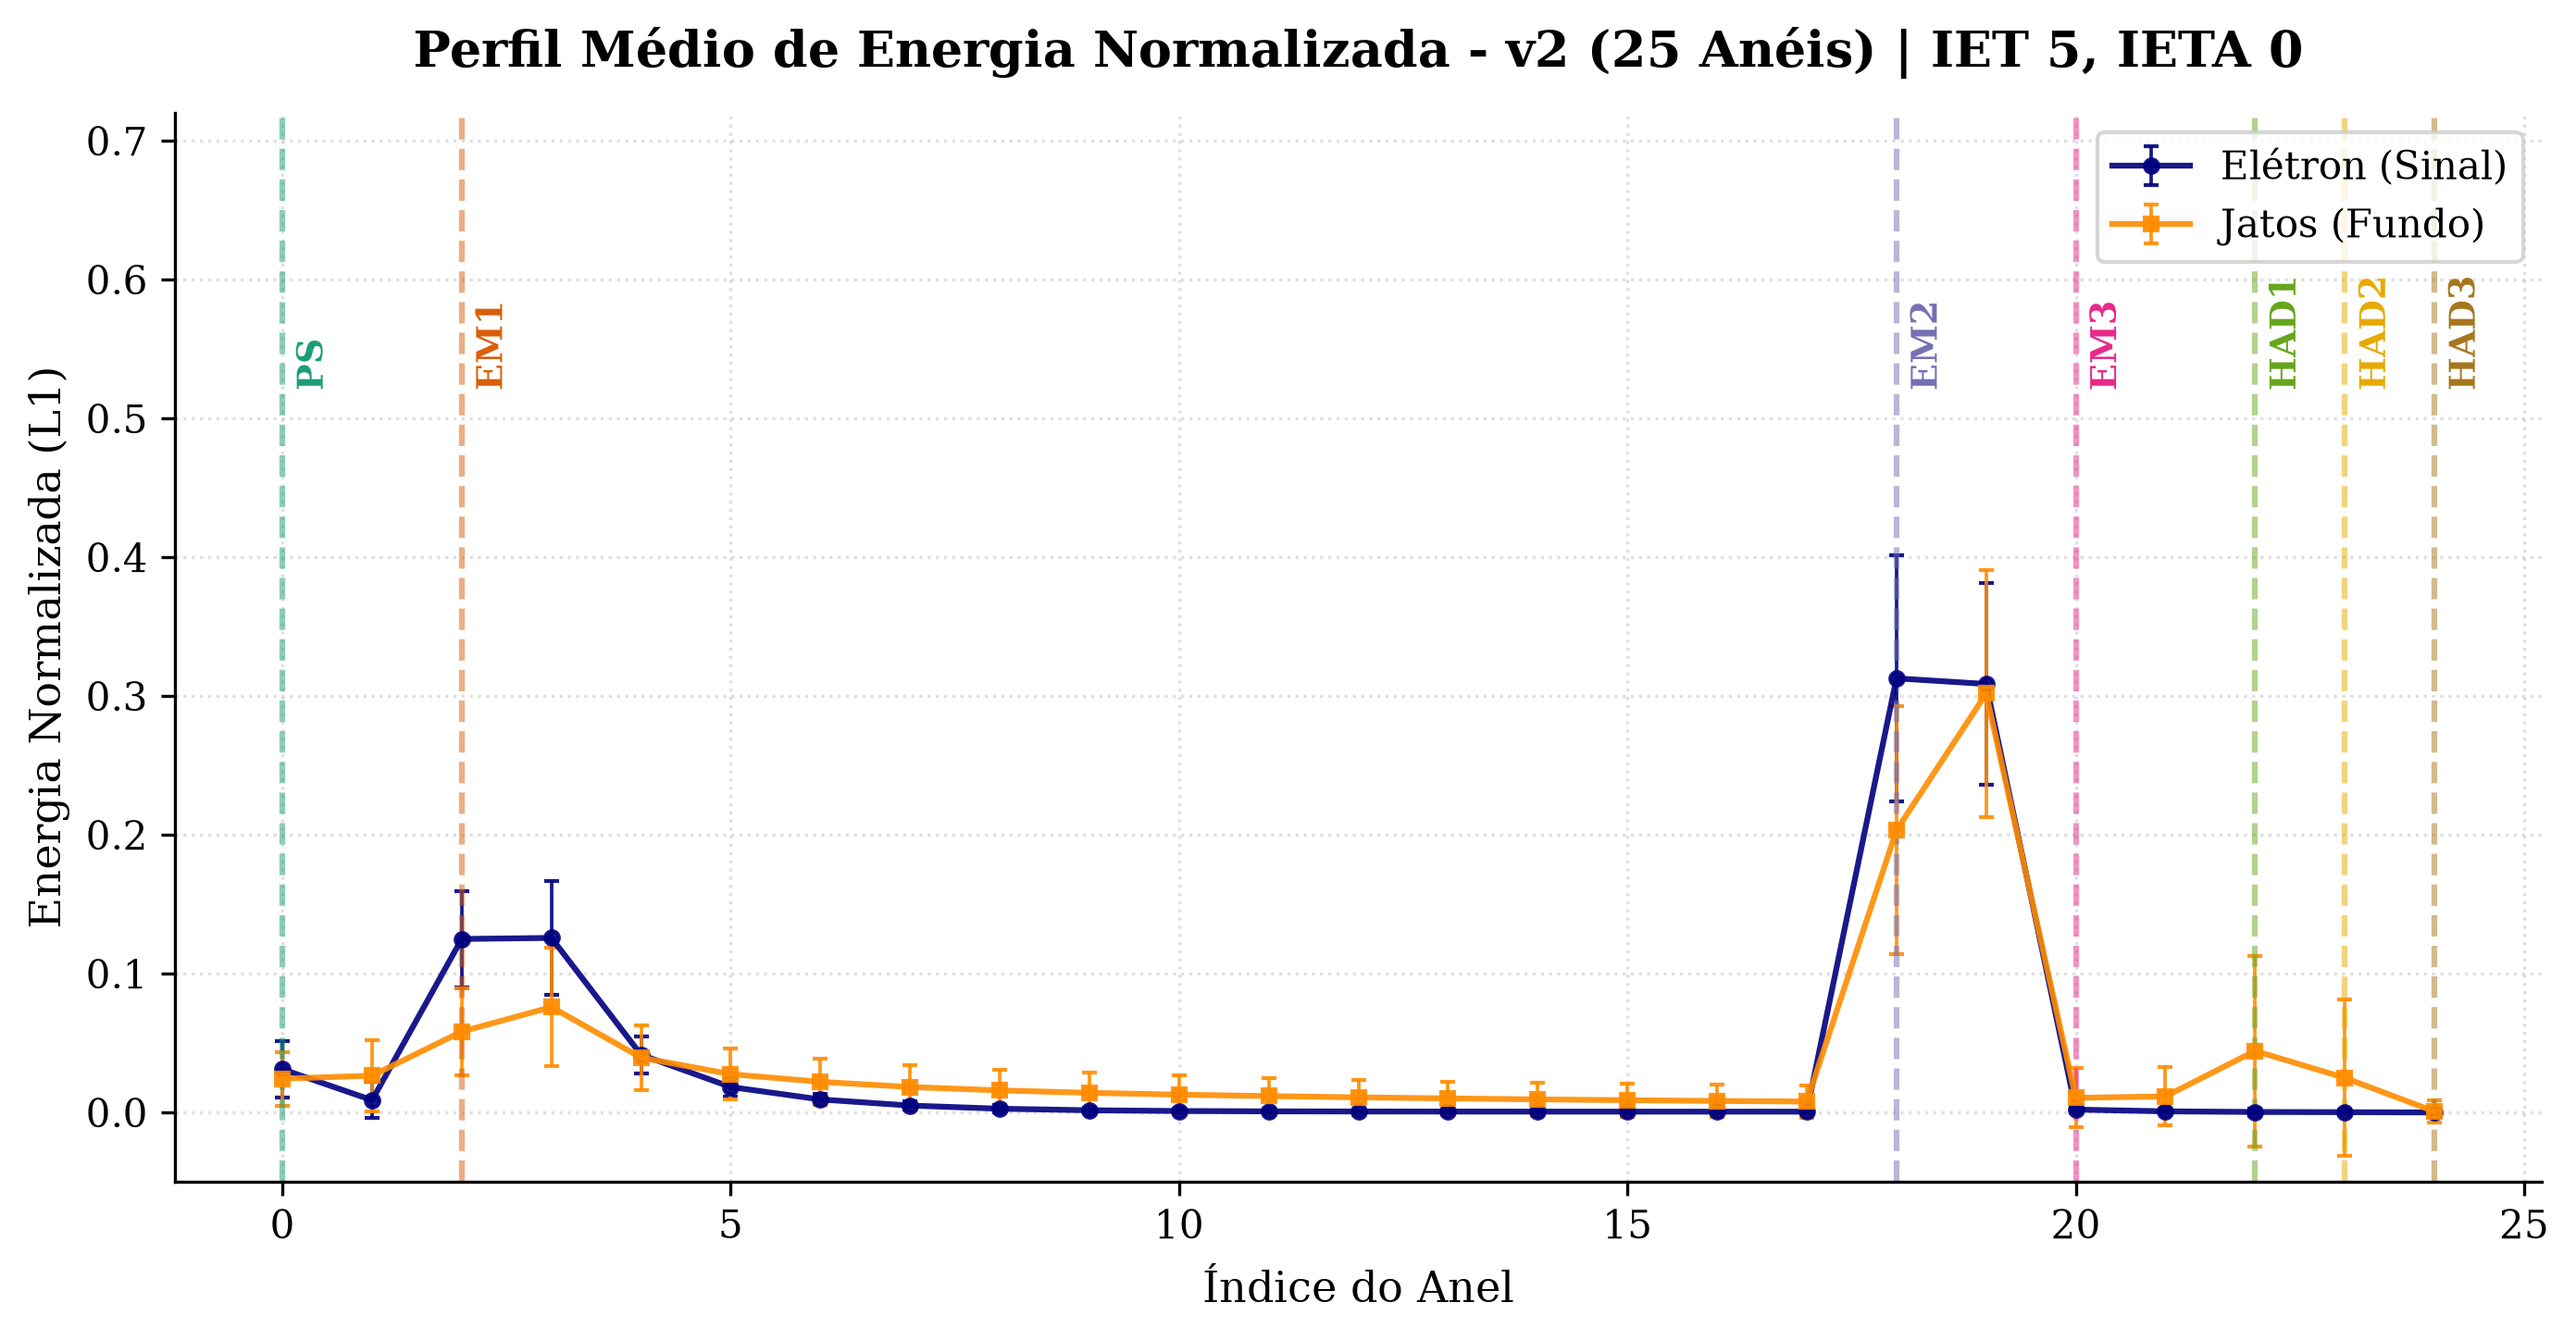


--- sensitivity_validation.png ---


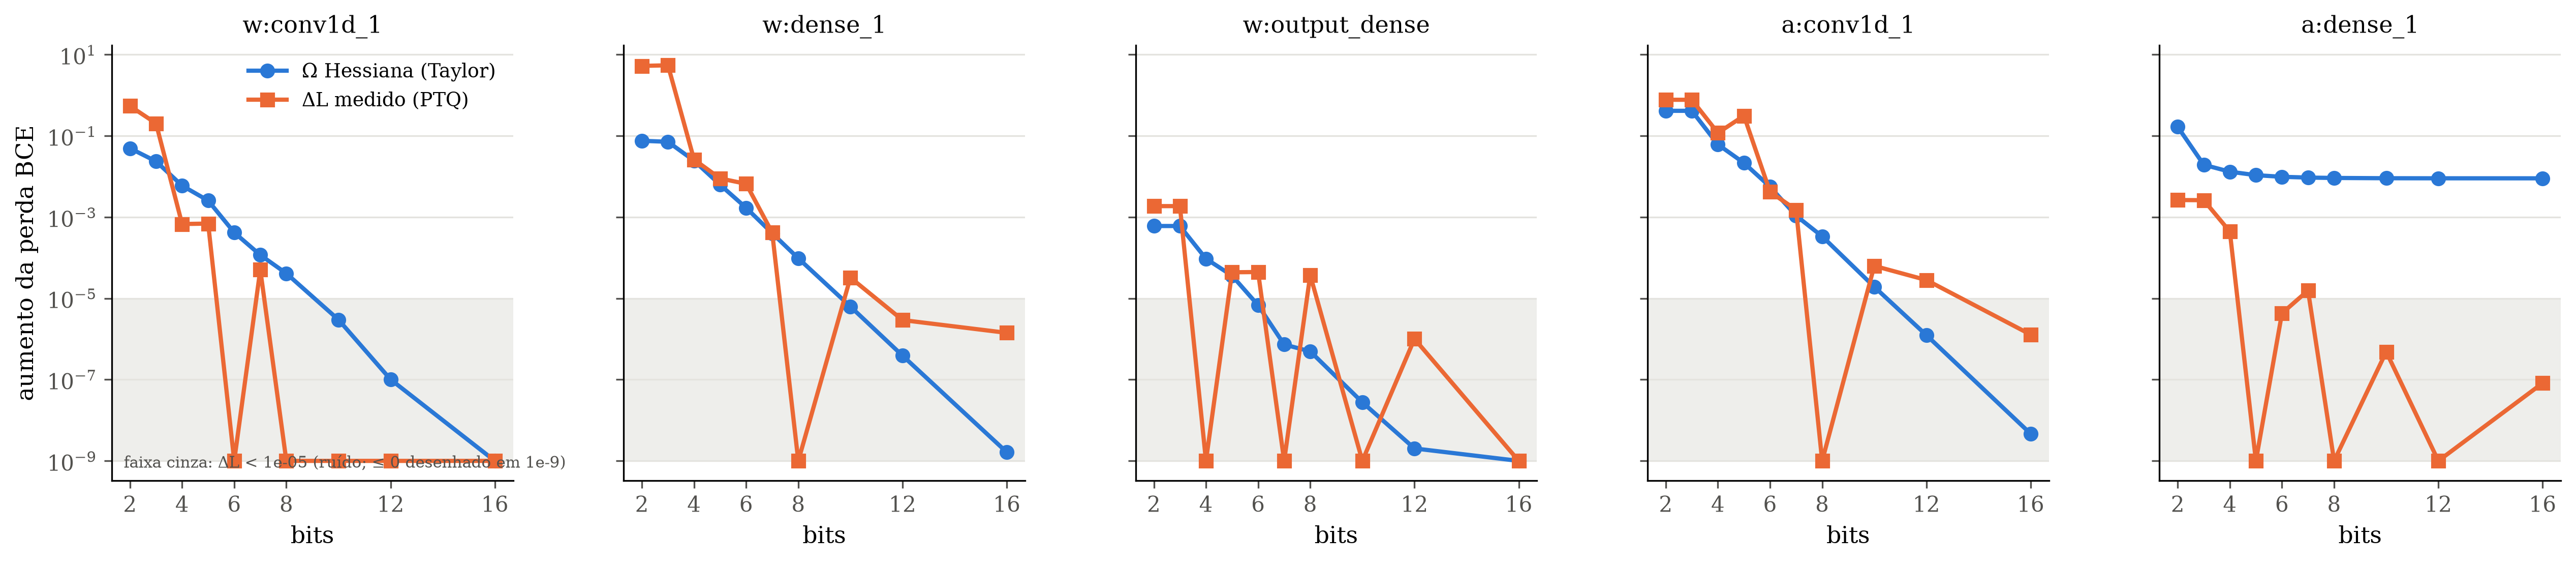


--- kkt_primal_dual_evolution.png ---


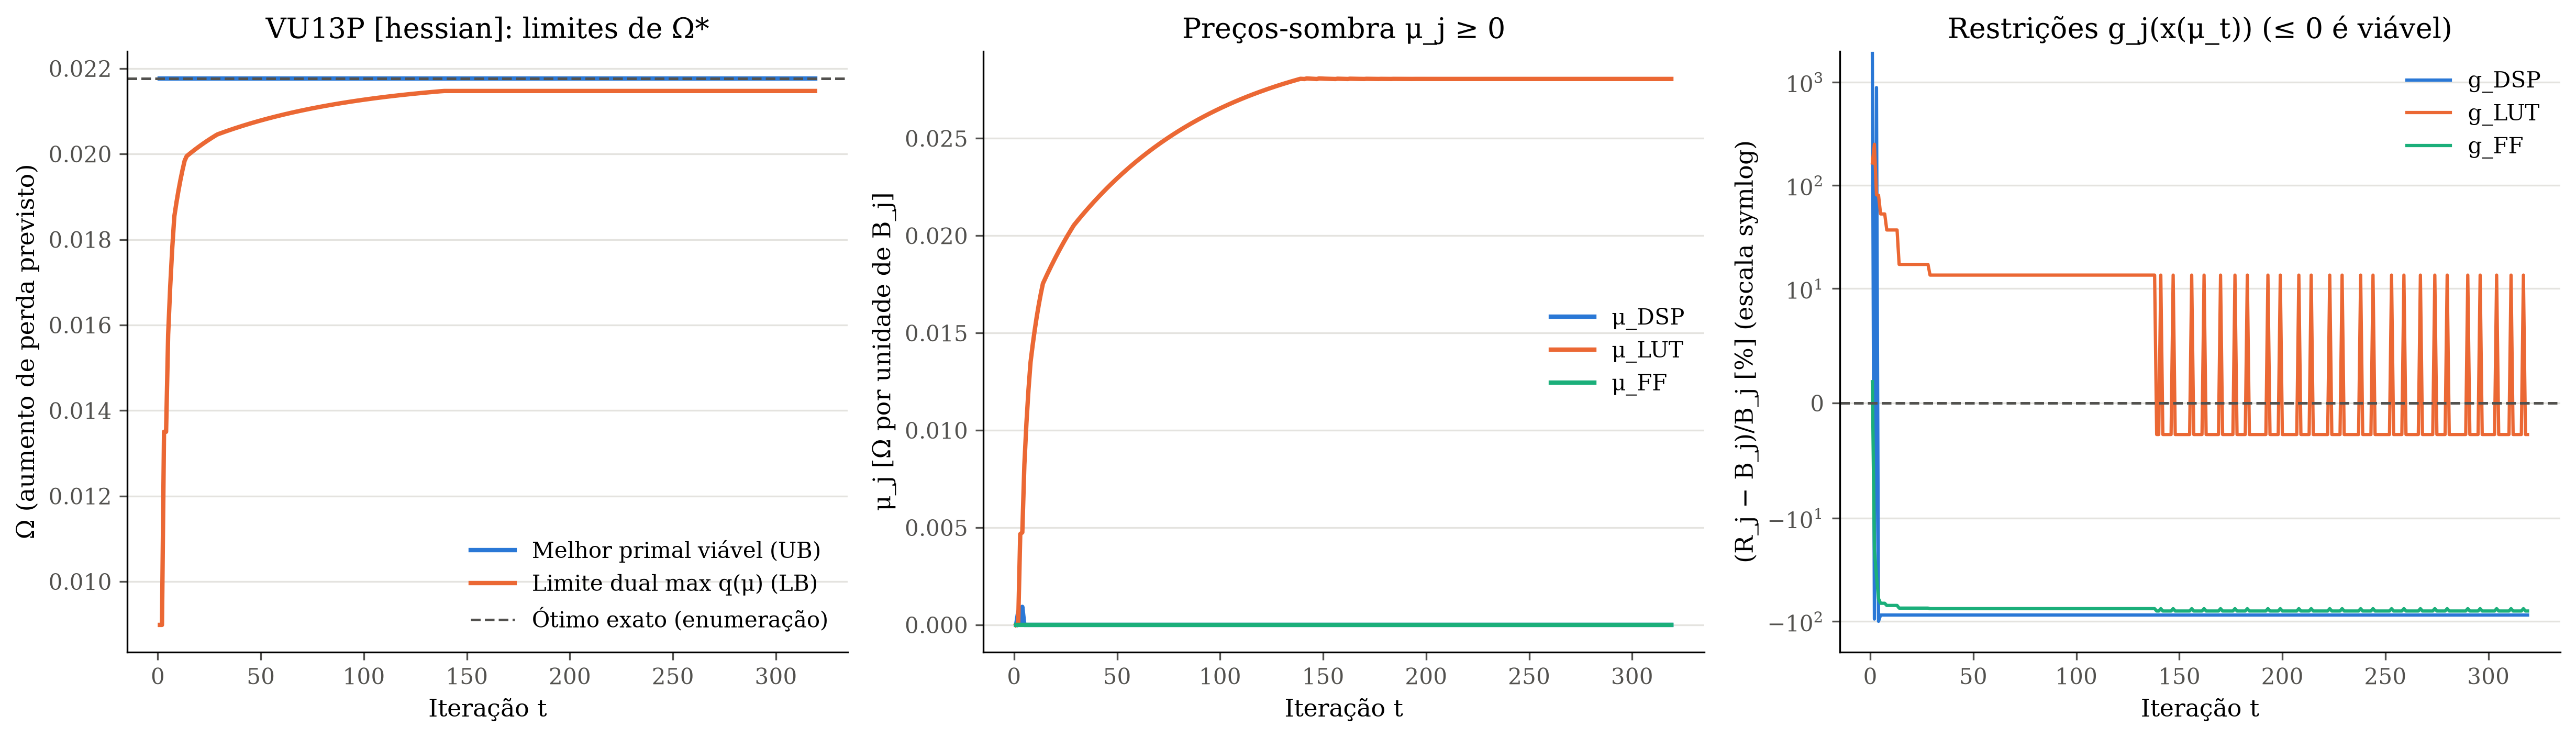


--- kkt_primal_dual_evolution_measured.png ---


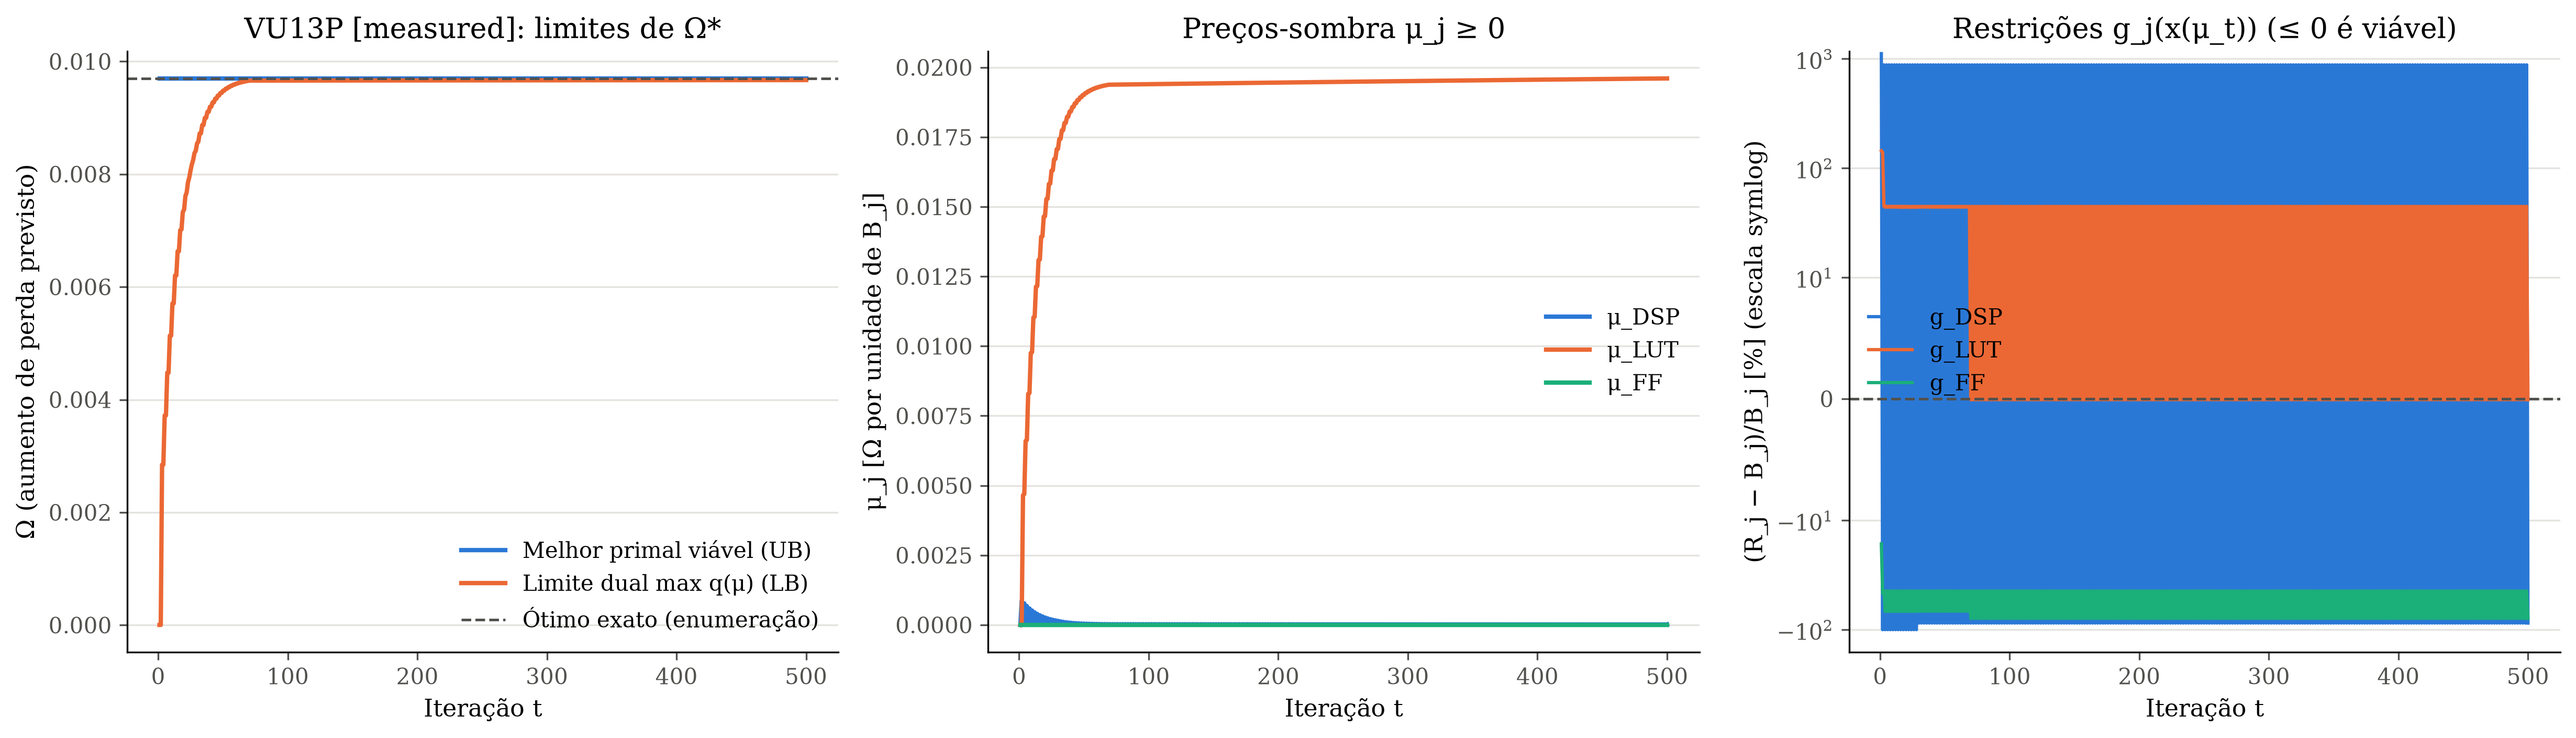


--- pareto_sp_vs_lut.png ---


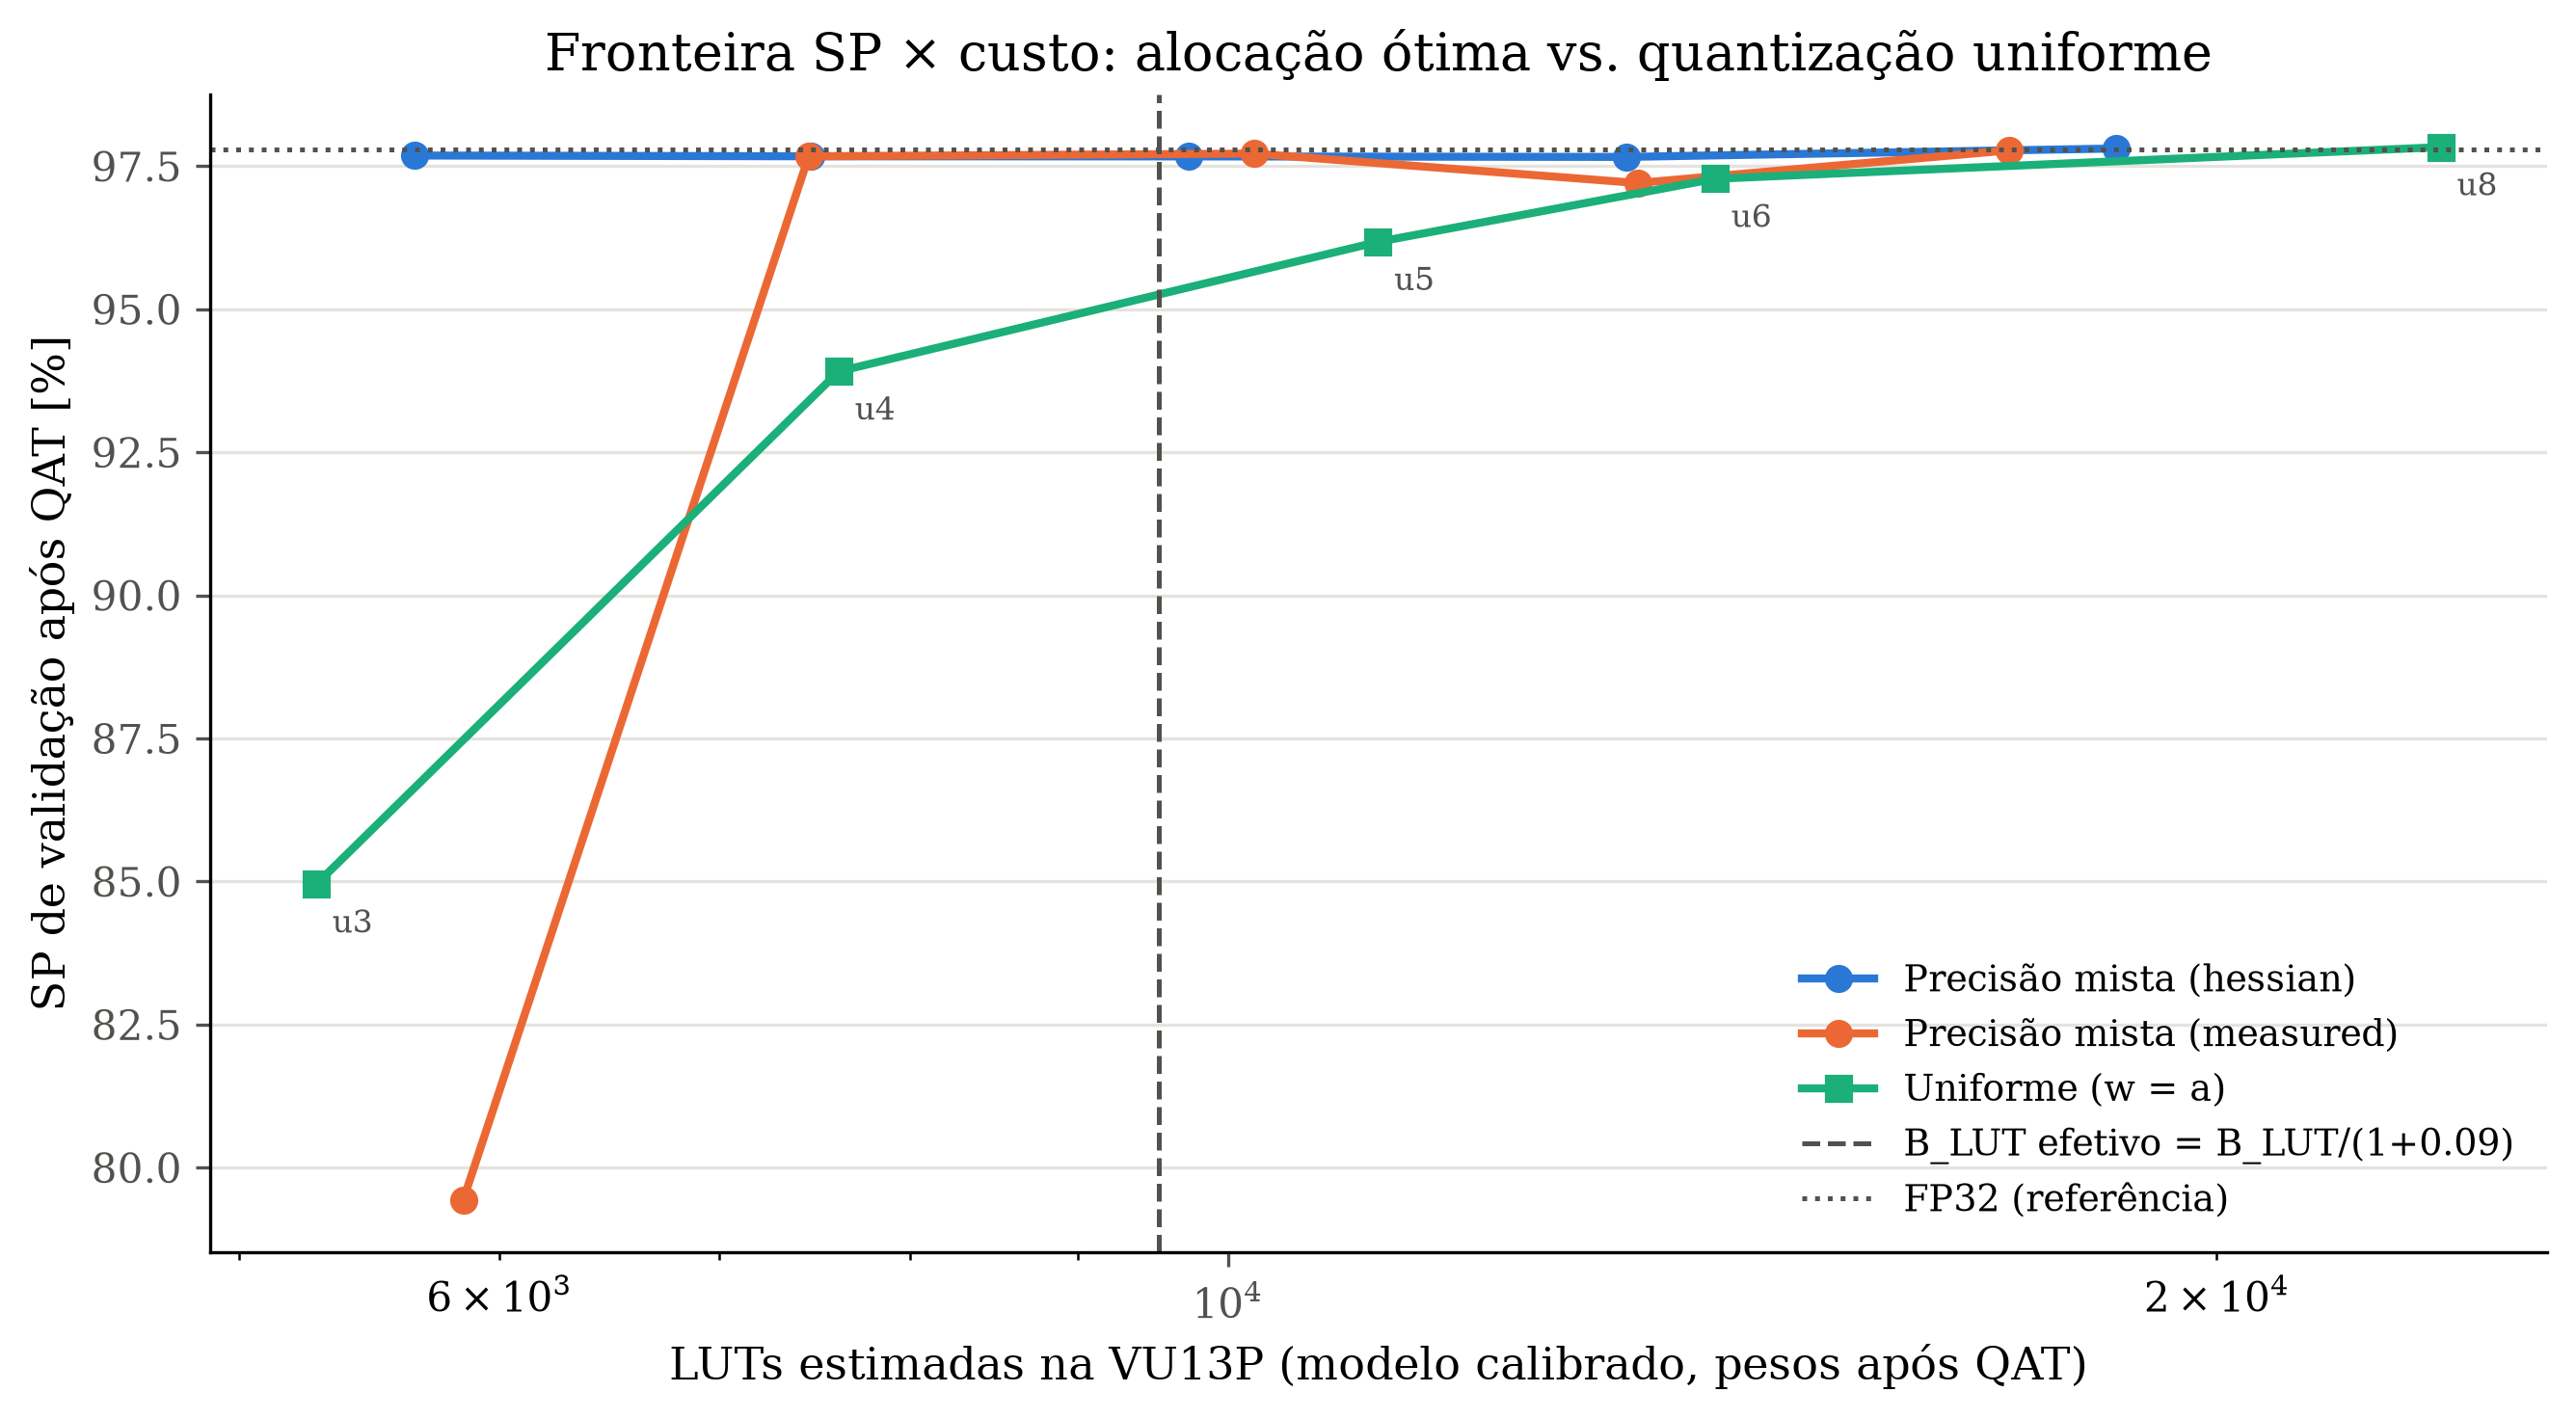


--- vu13p_resource_utilization.png ---


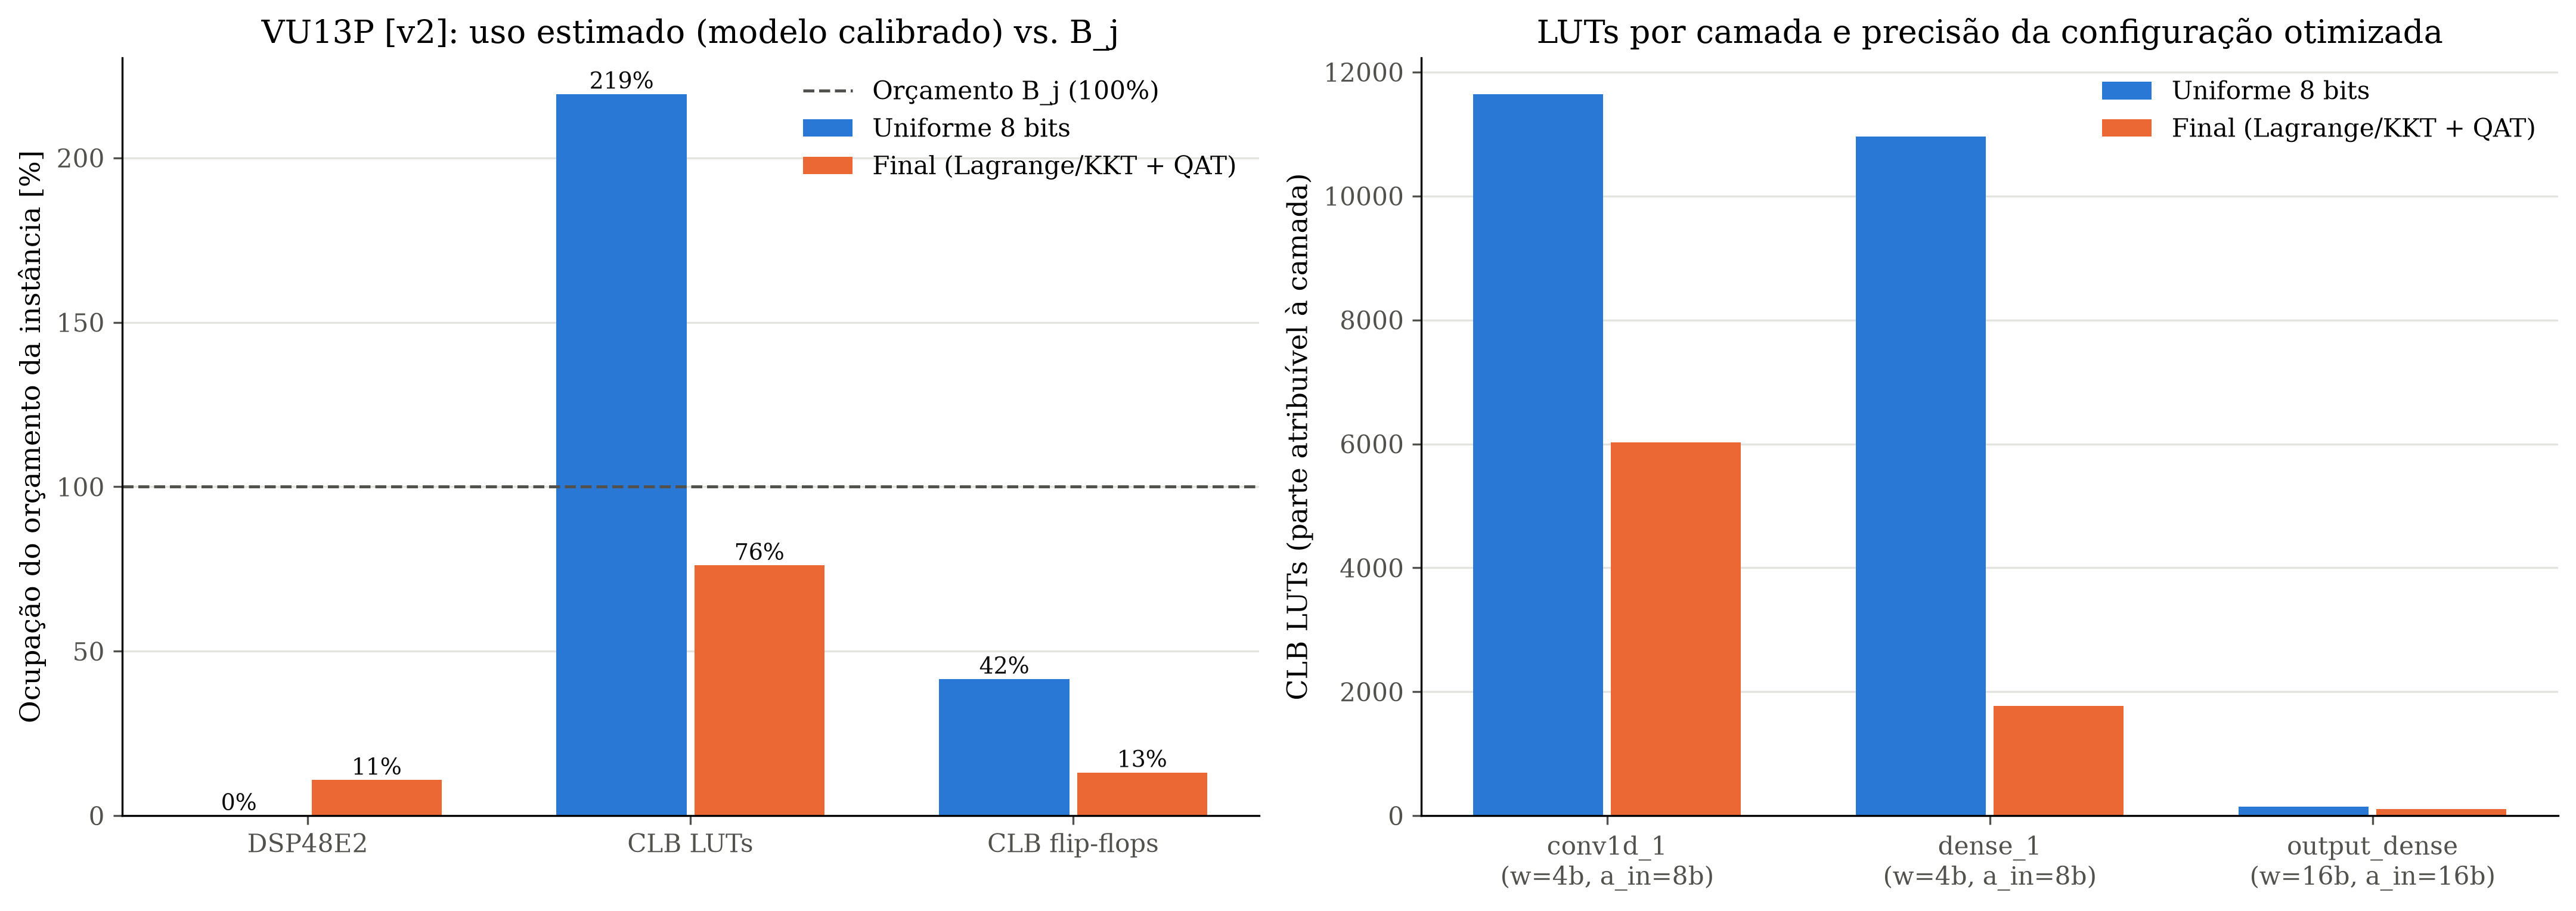


--- learning_curves.png ---


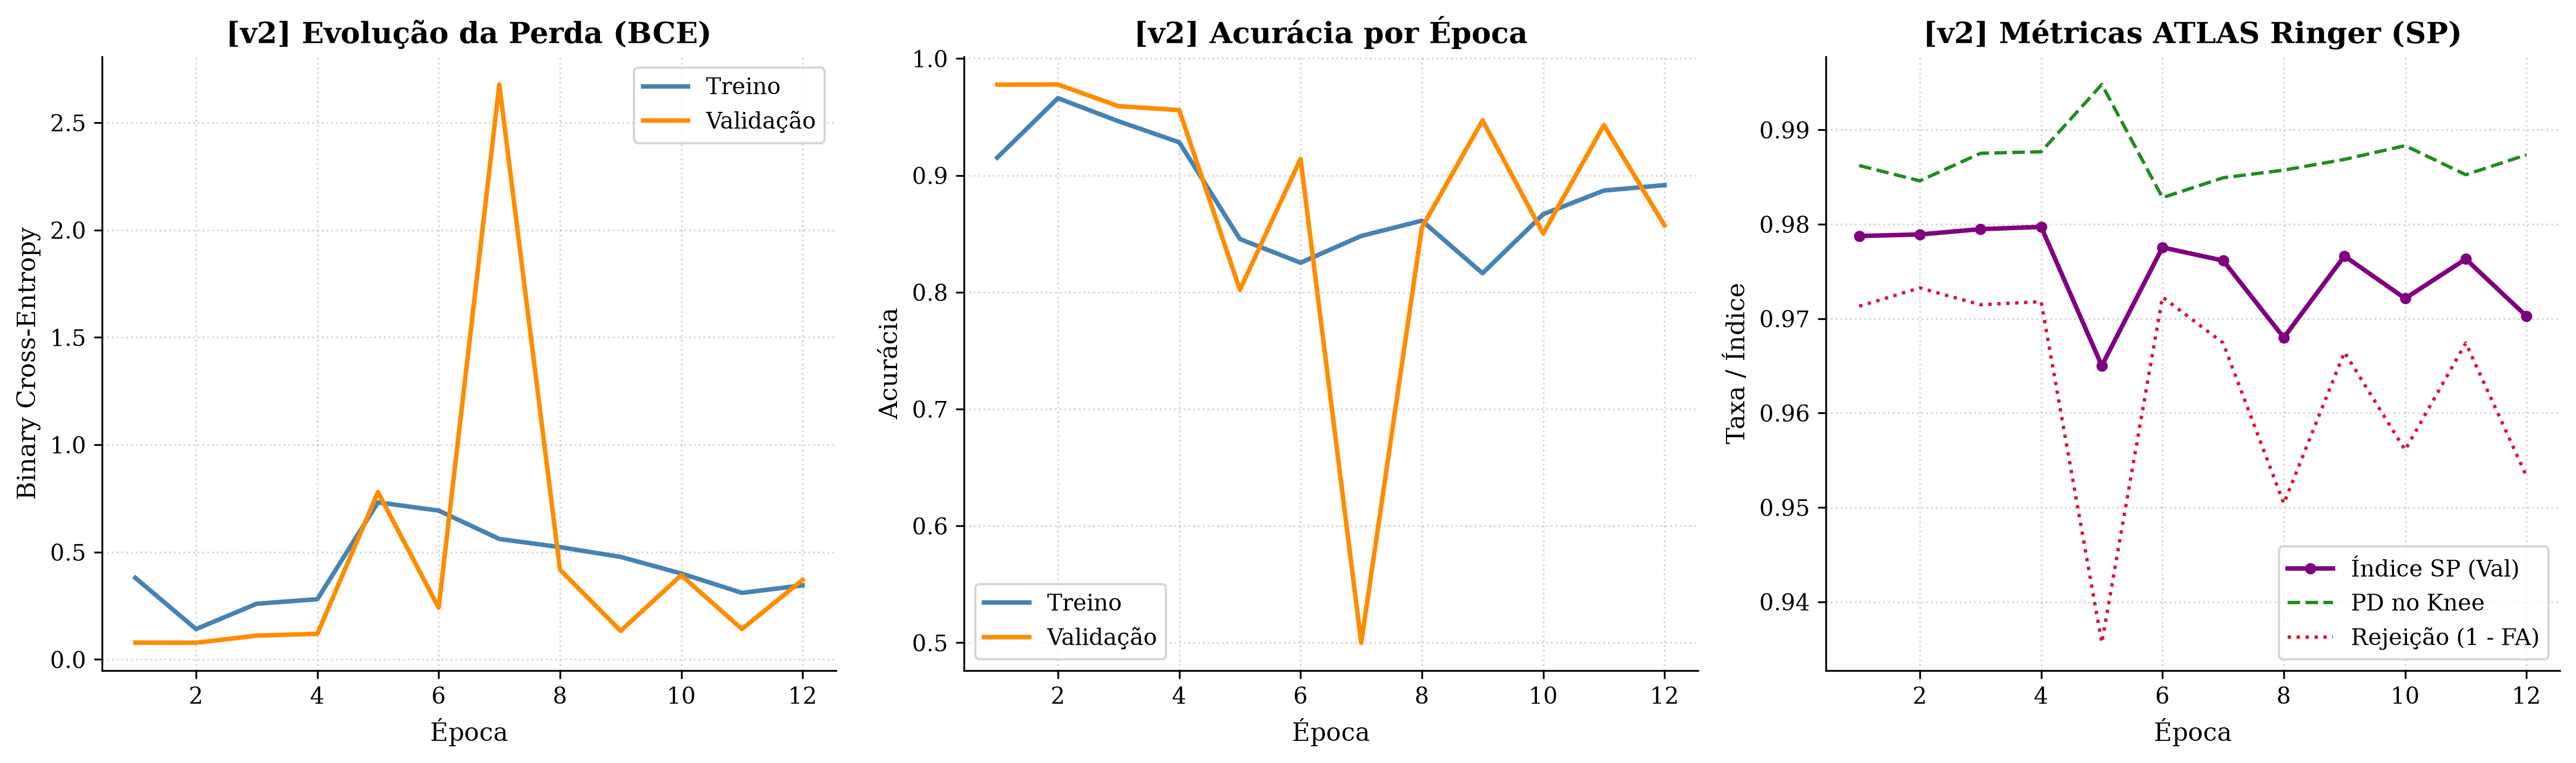


--- roc_best_model.png ---


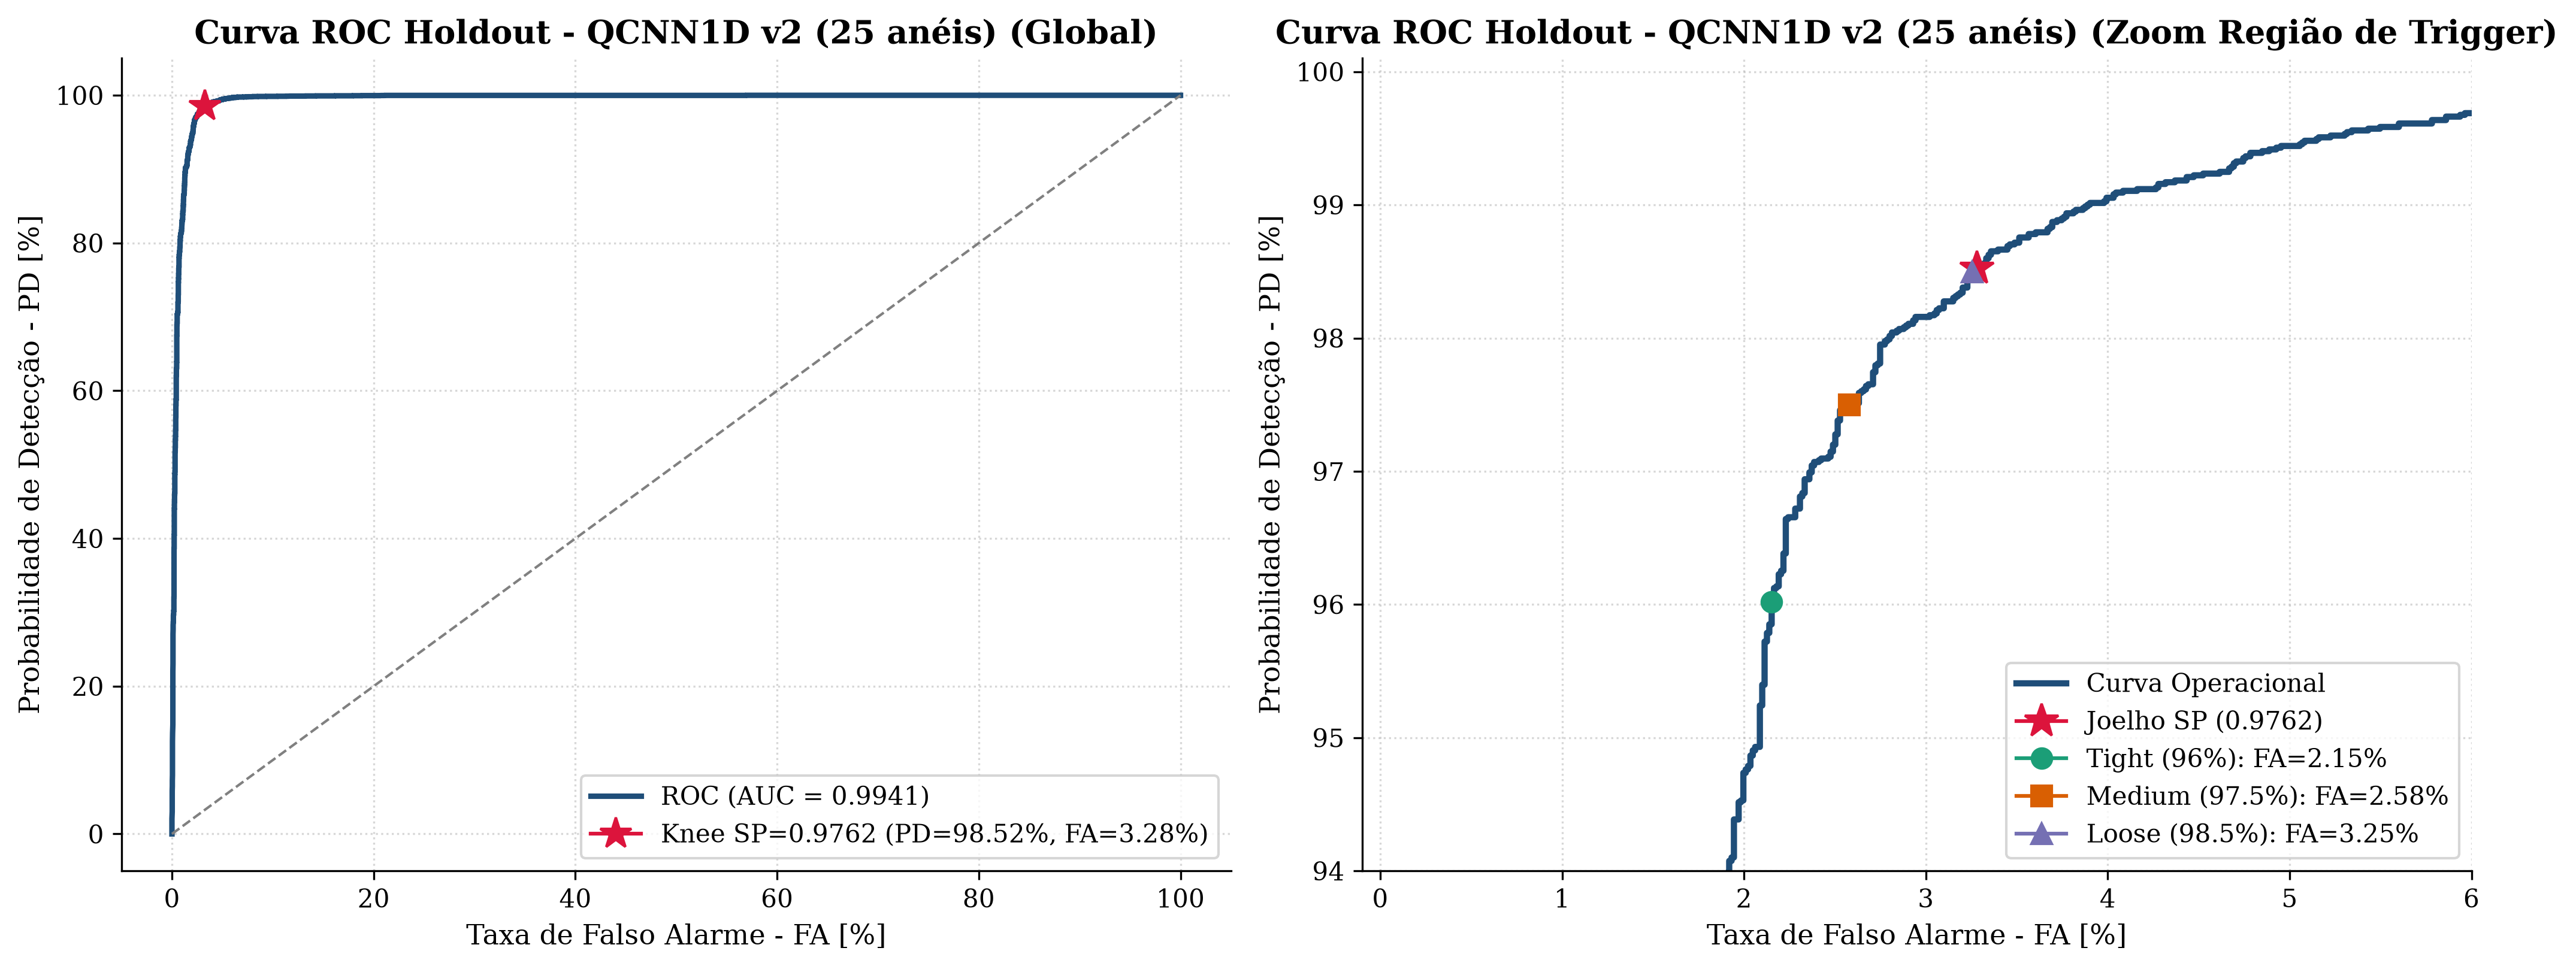


--- roc_duel_fp32_vs_kkt.png ---


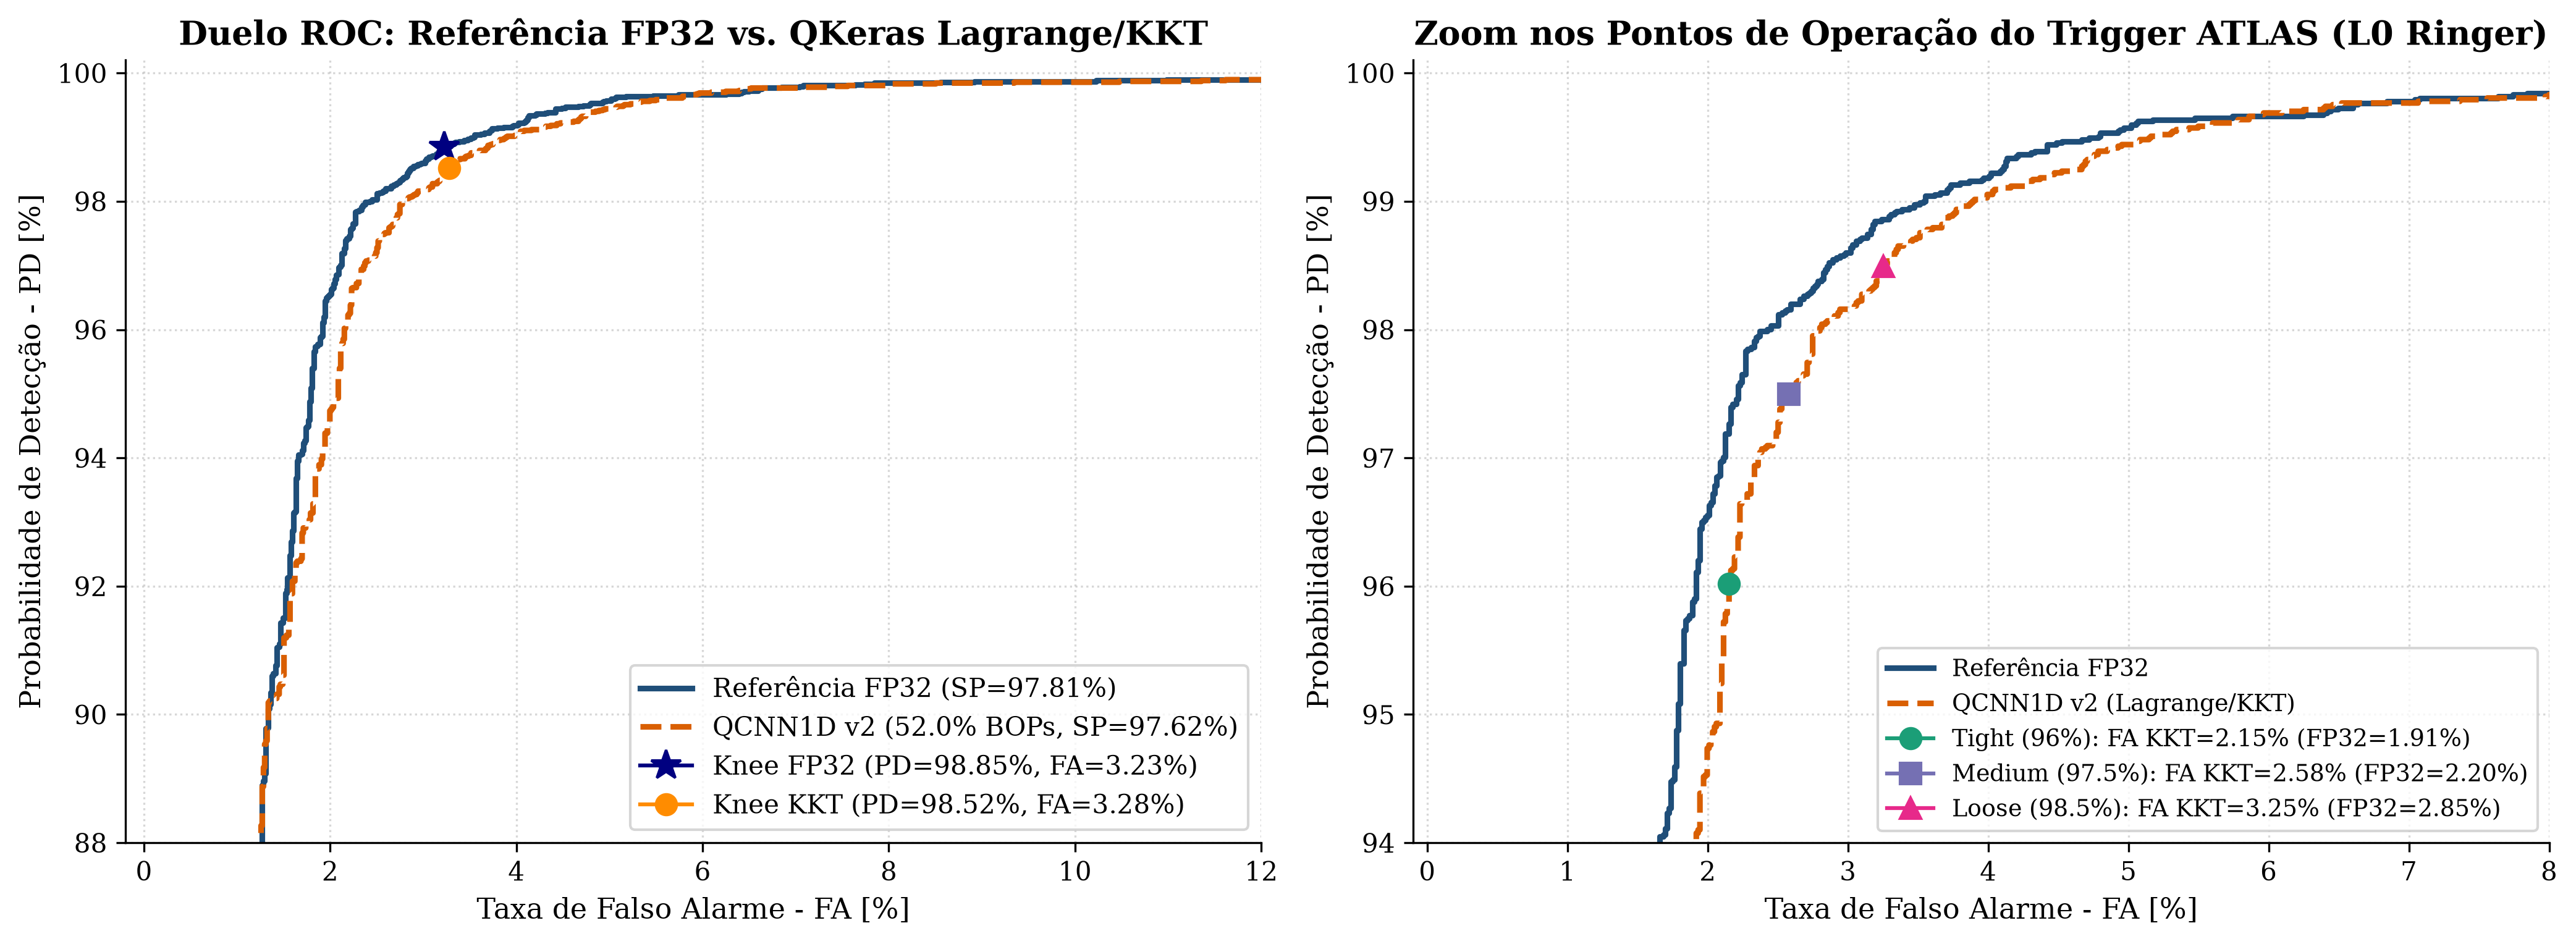


--- roc_cv_envelope.png ---


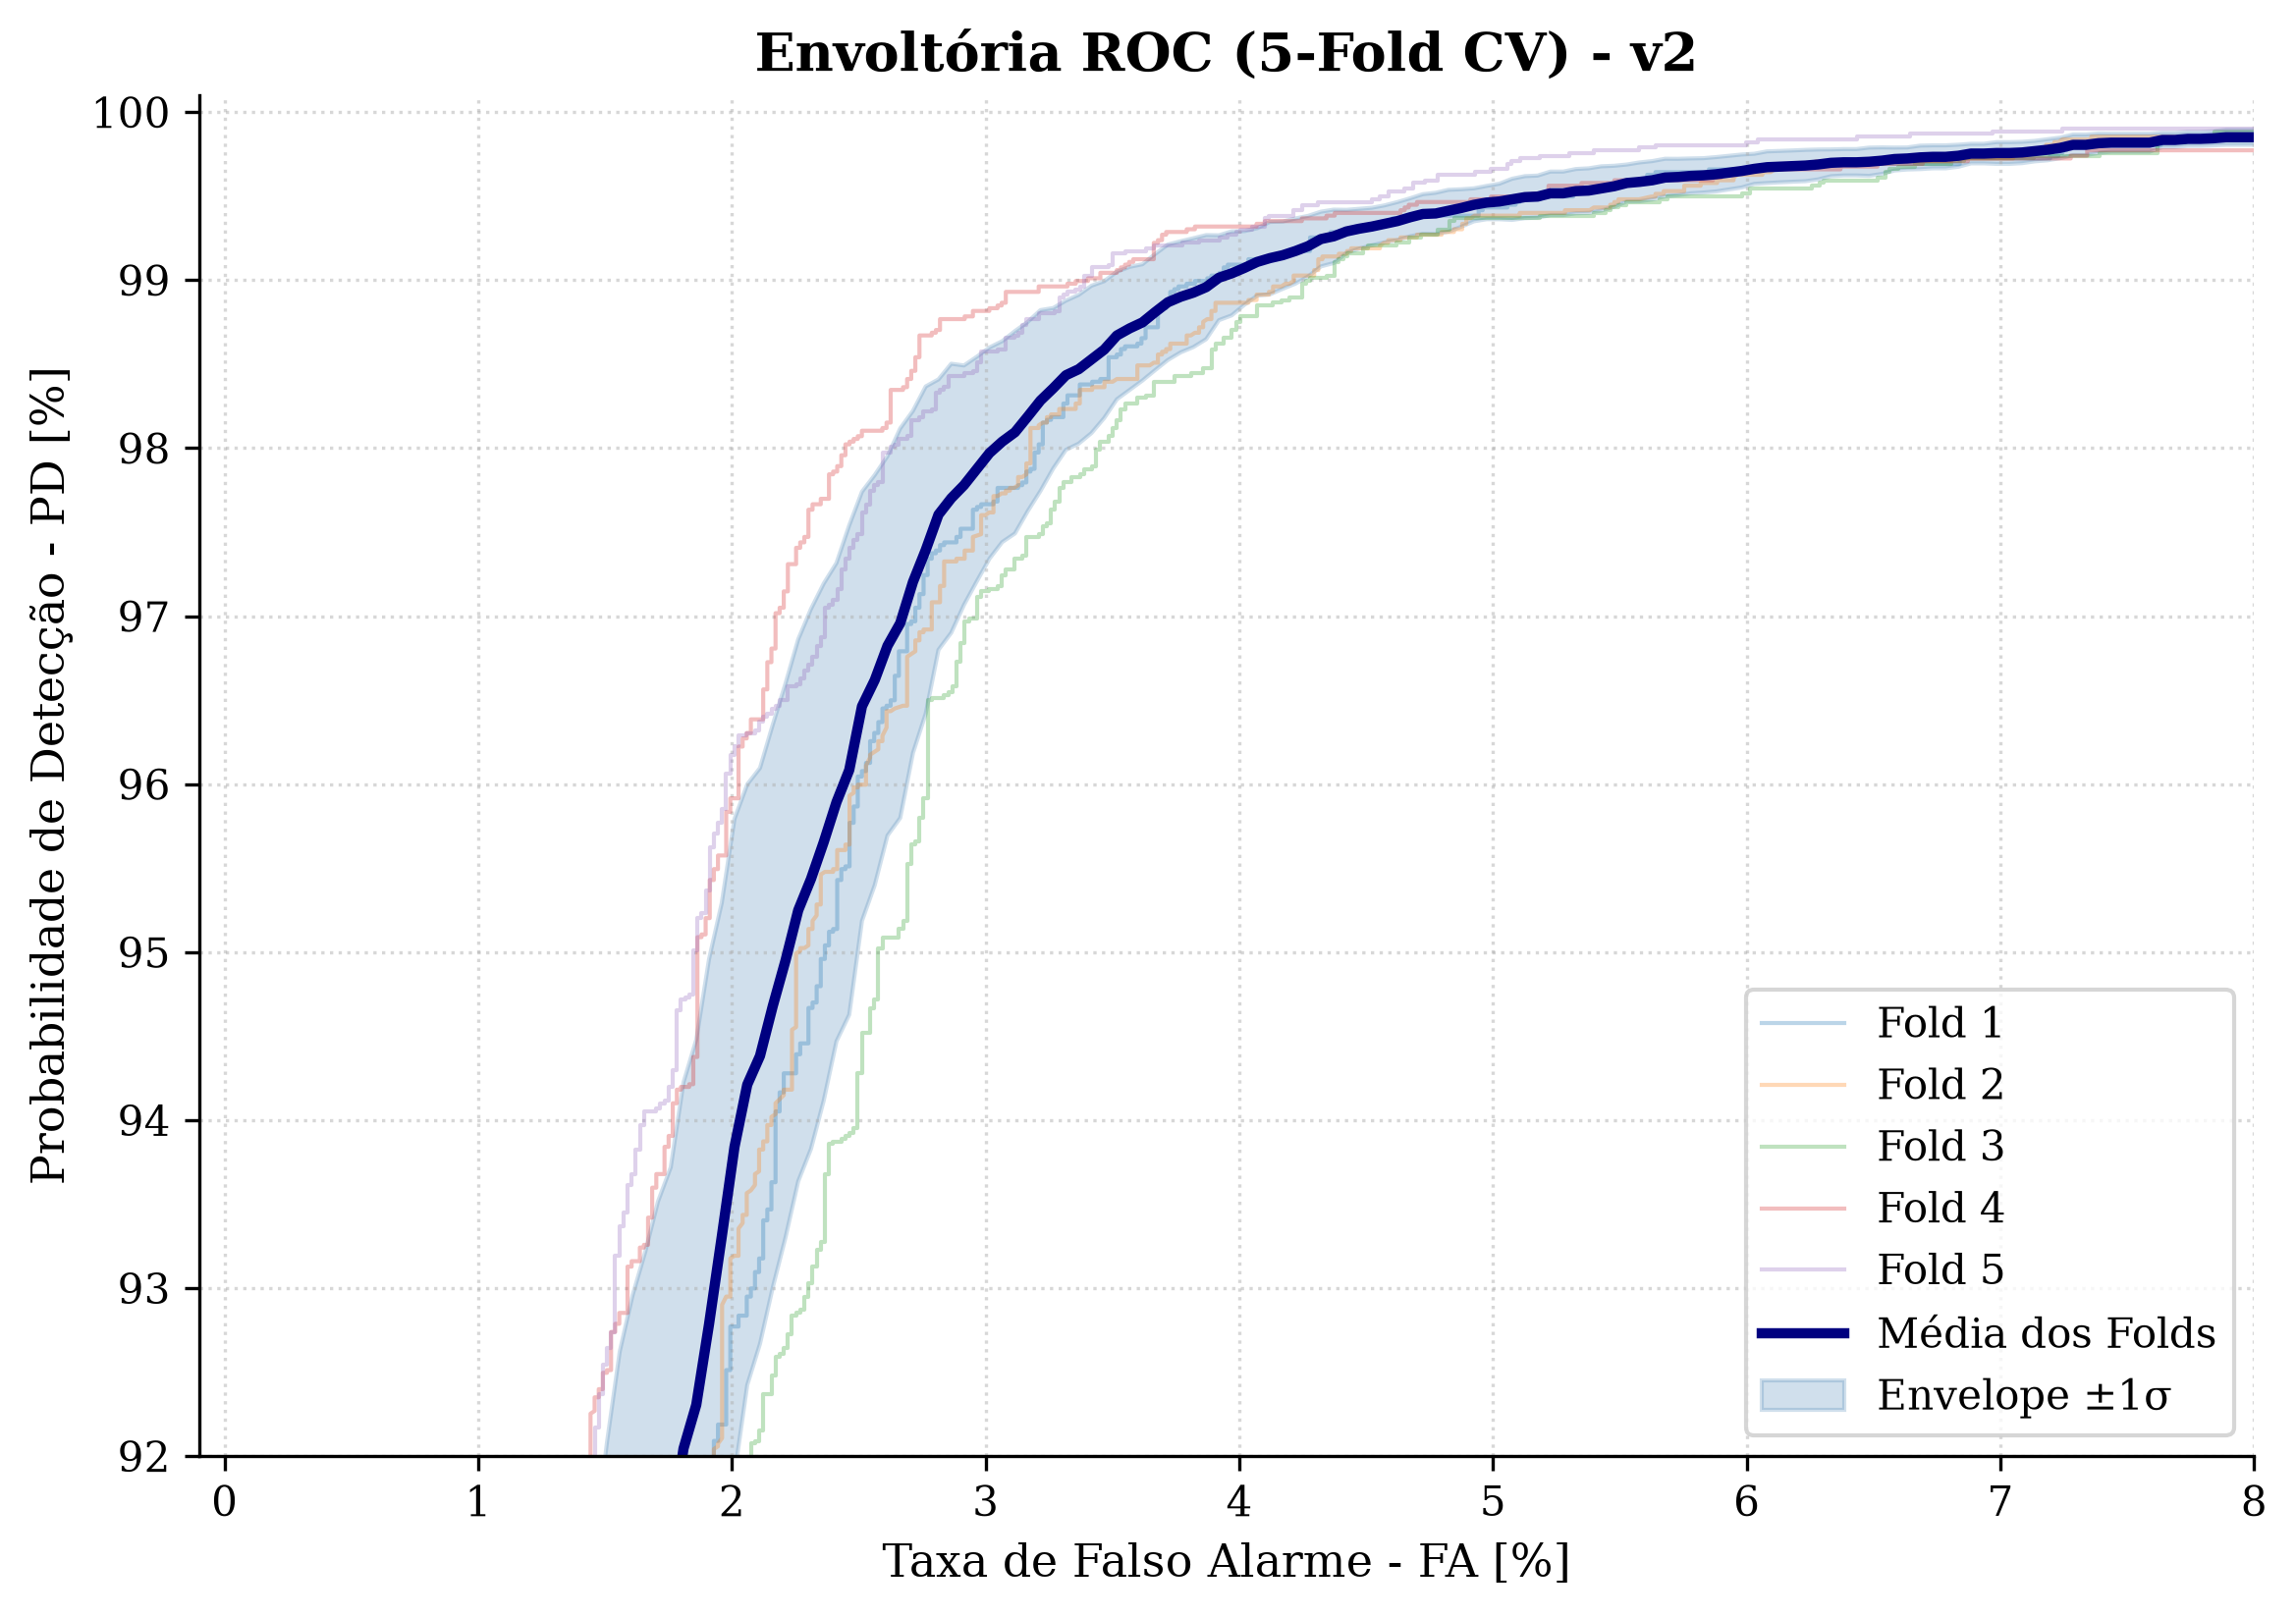


--- output_scores_hist.png ---


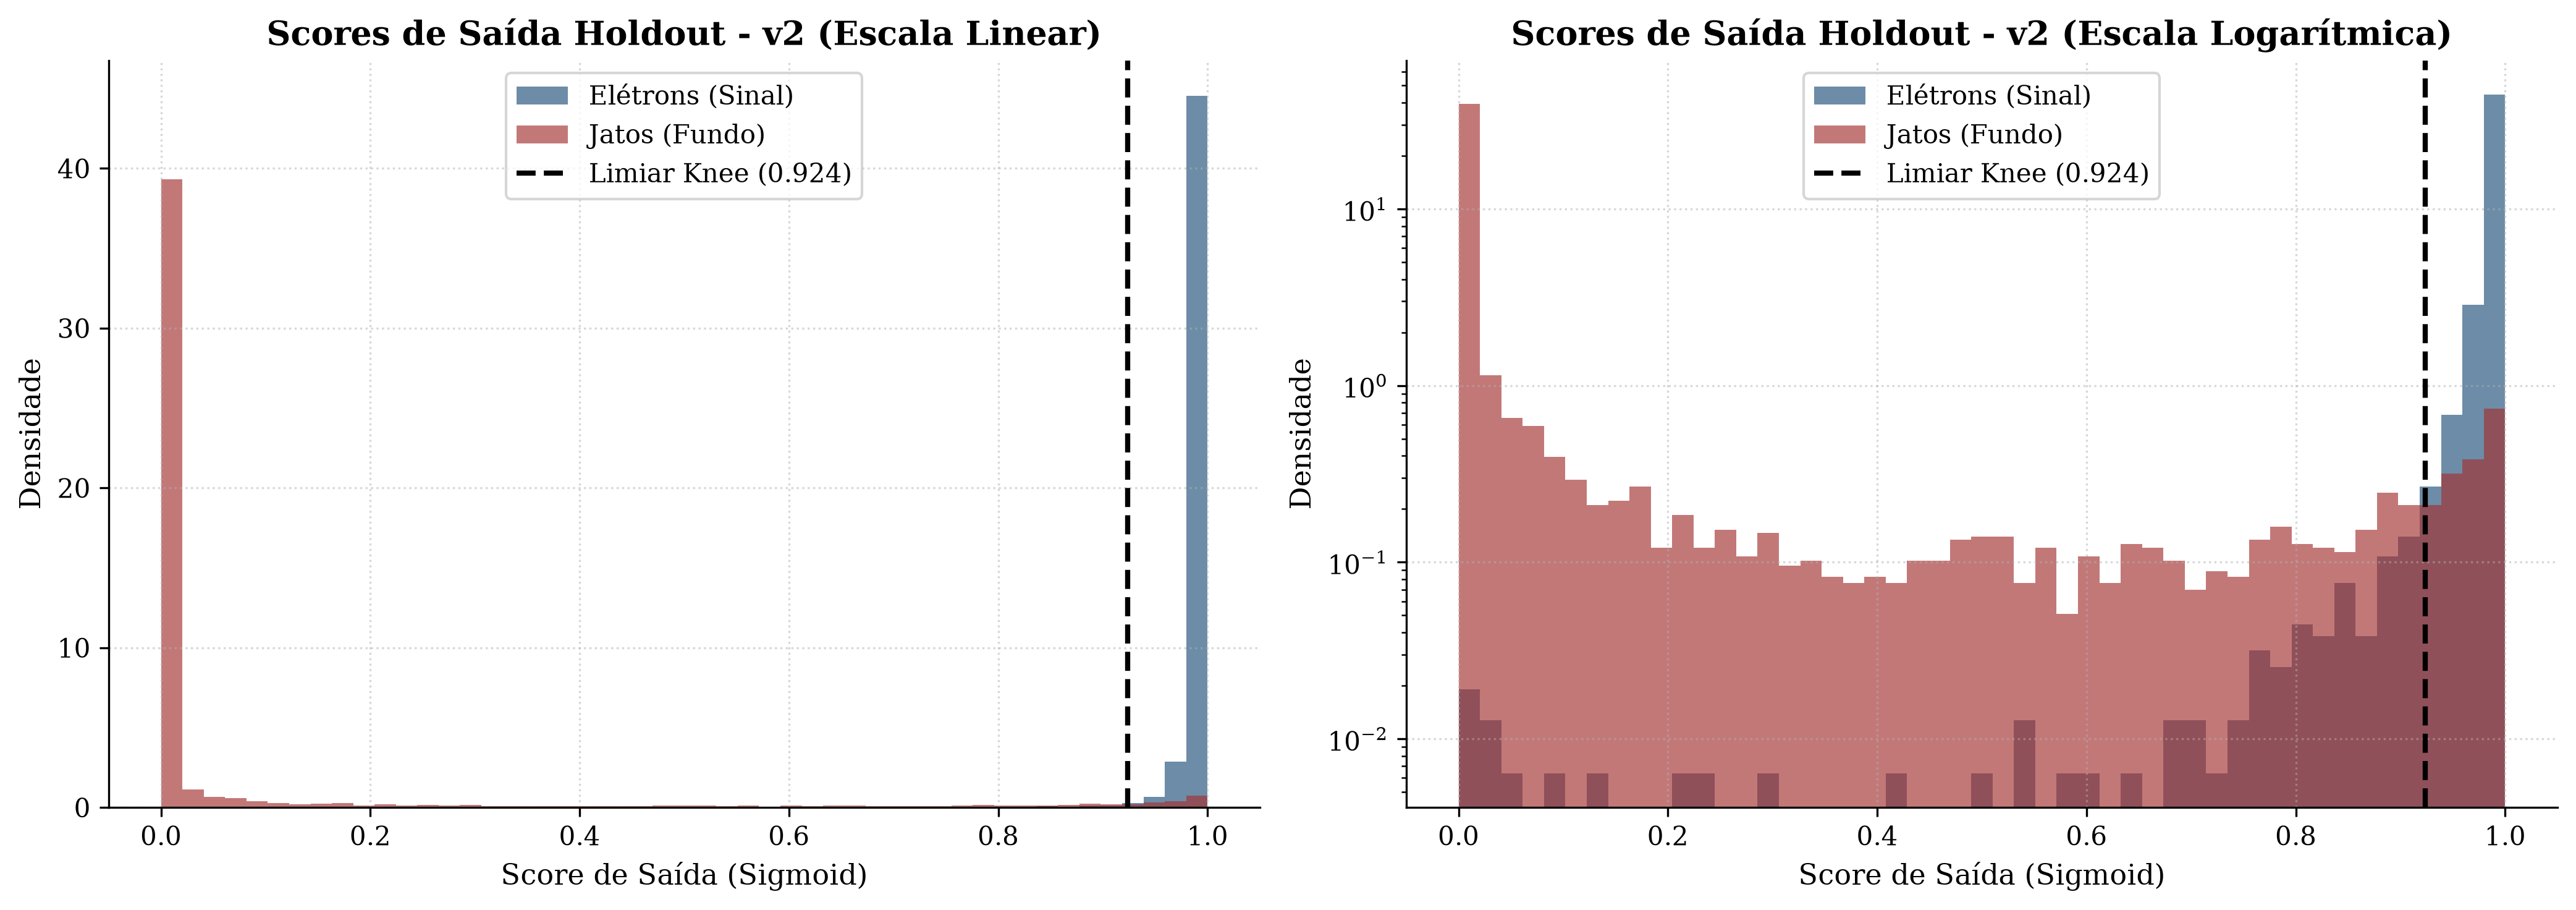


--- confusion_matrix_knee.png ---


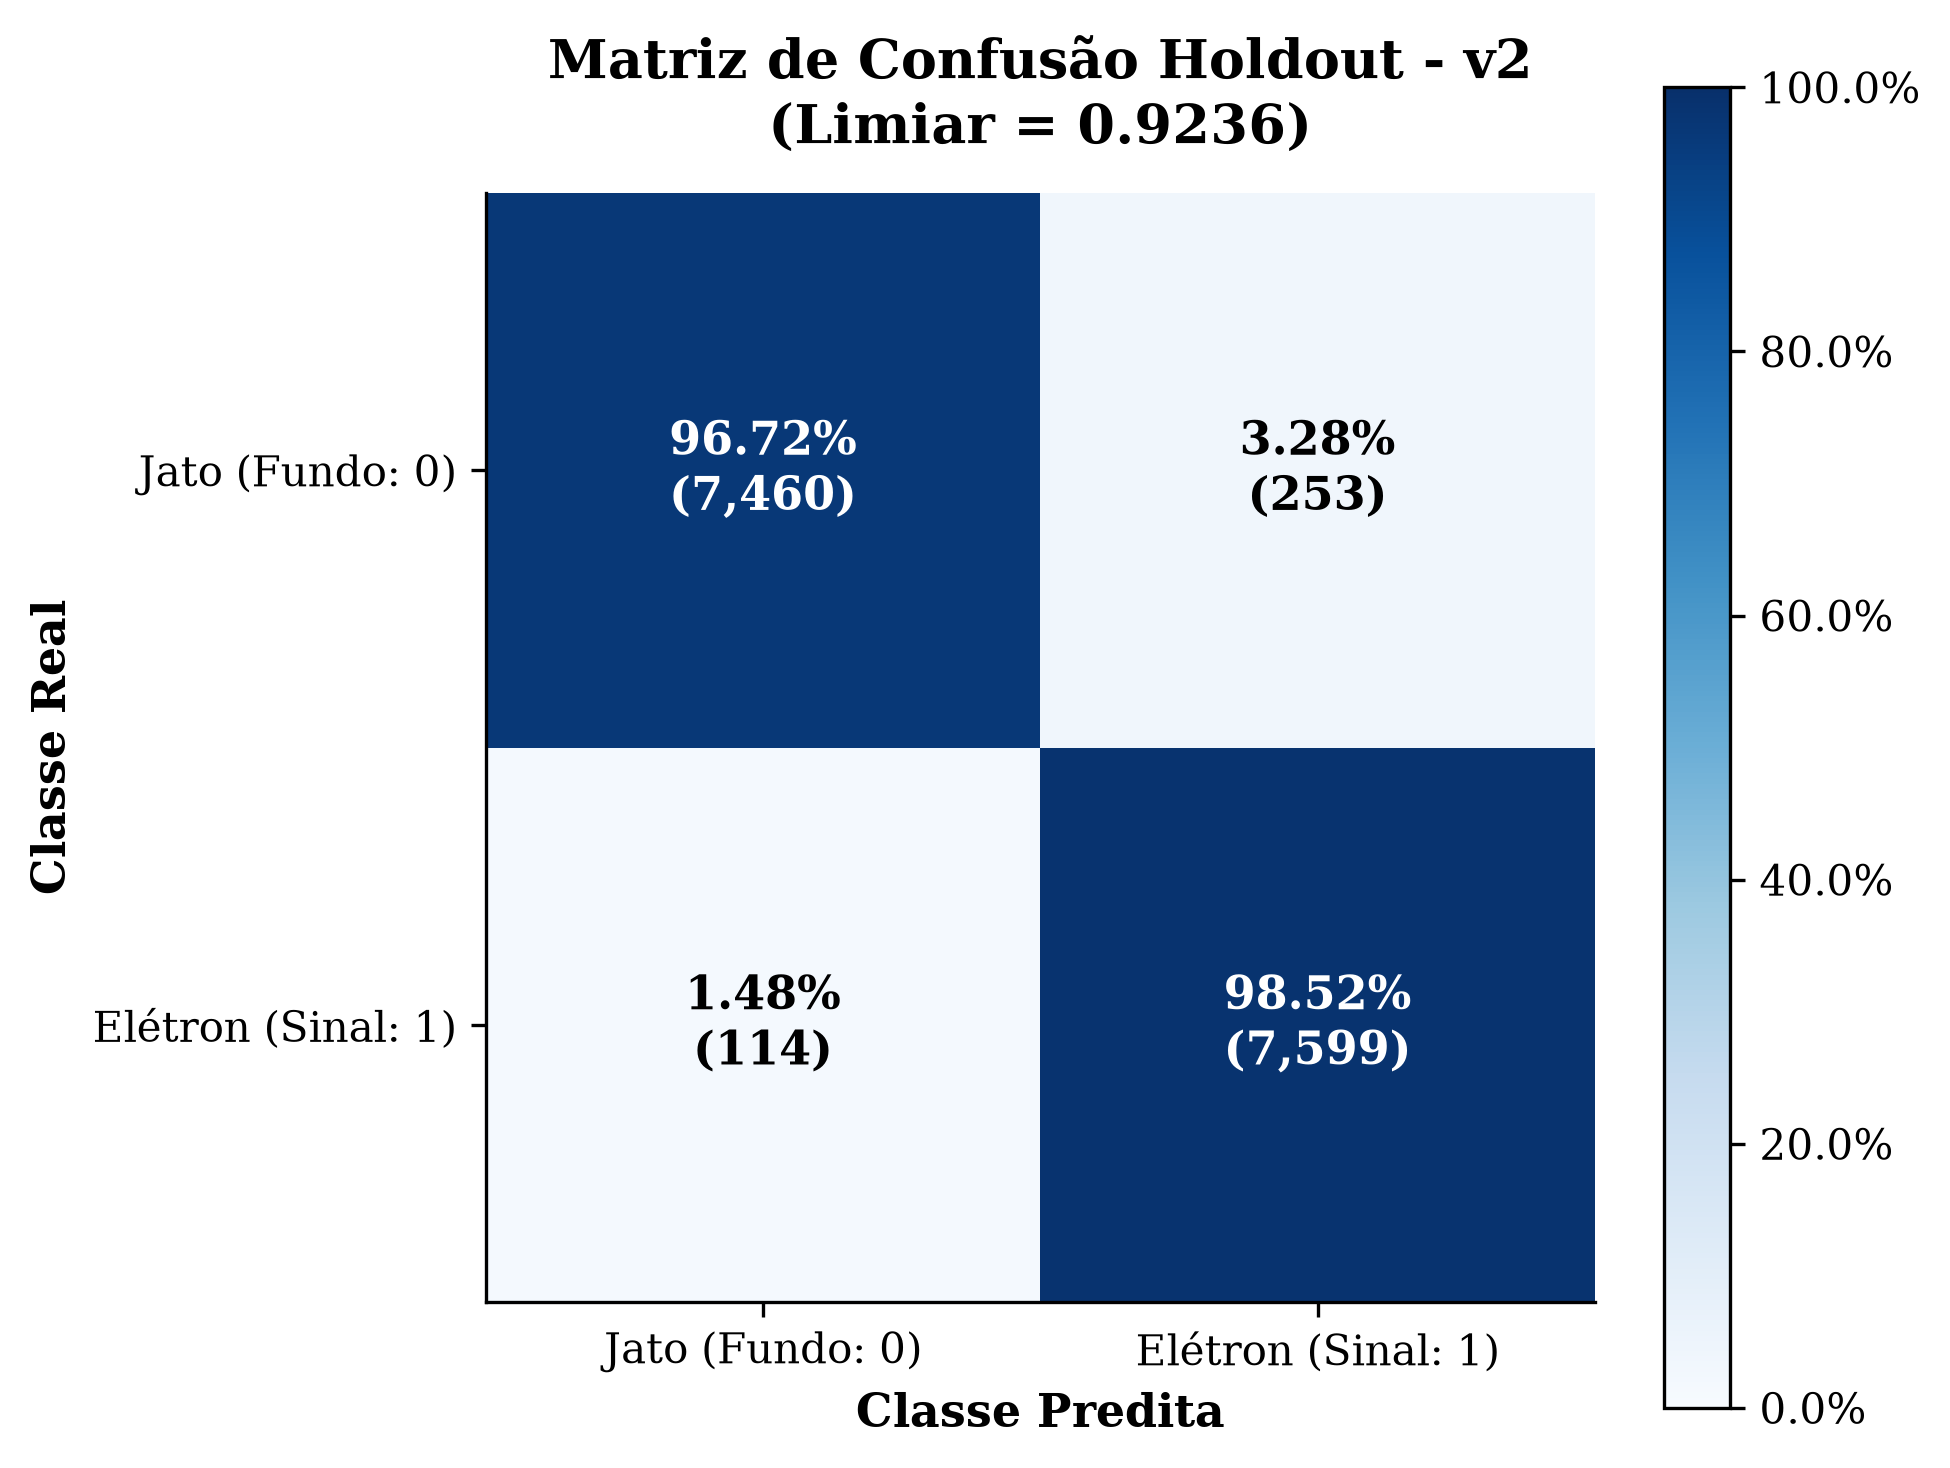


--- cv_boxplots.png ---


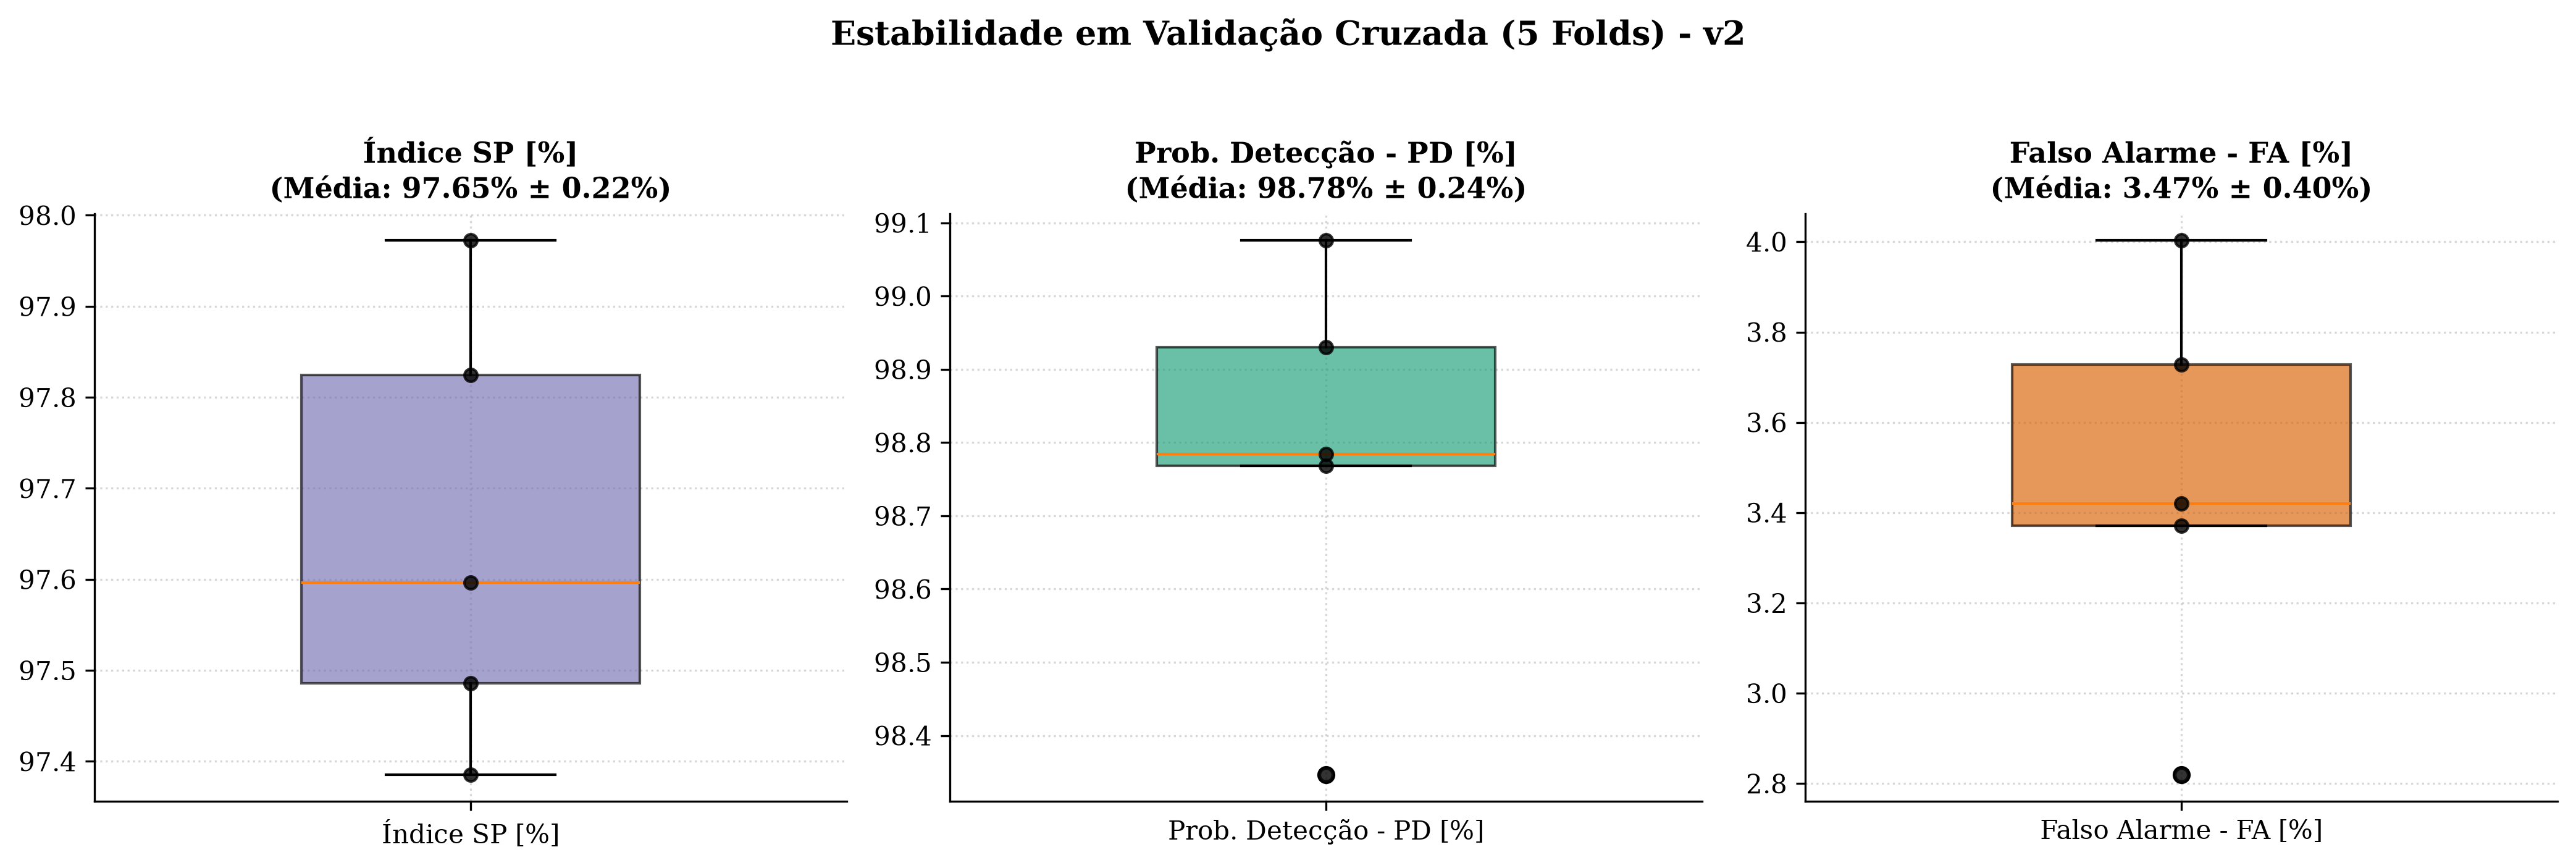


--- fa_per_fold_workpoints.png ---


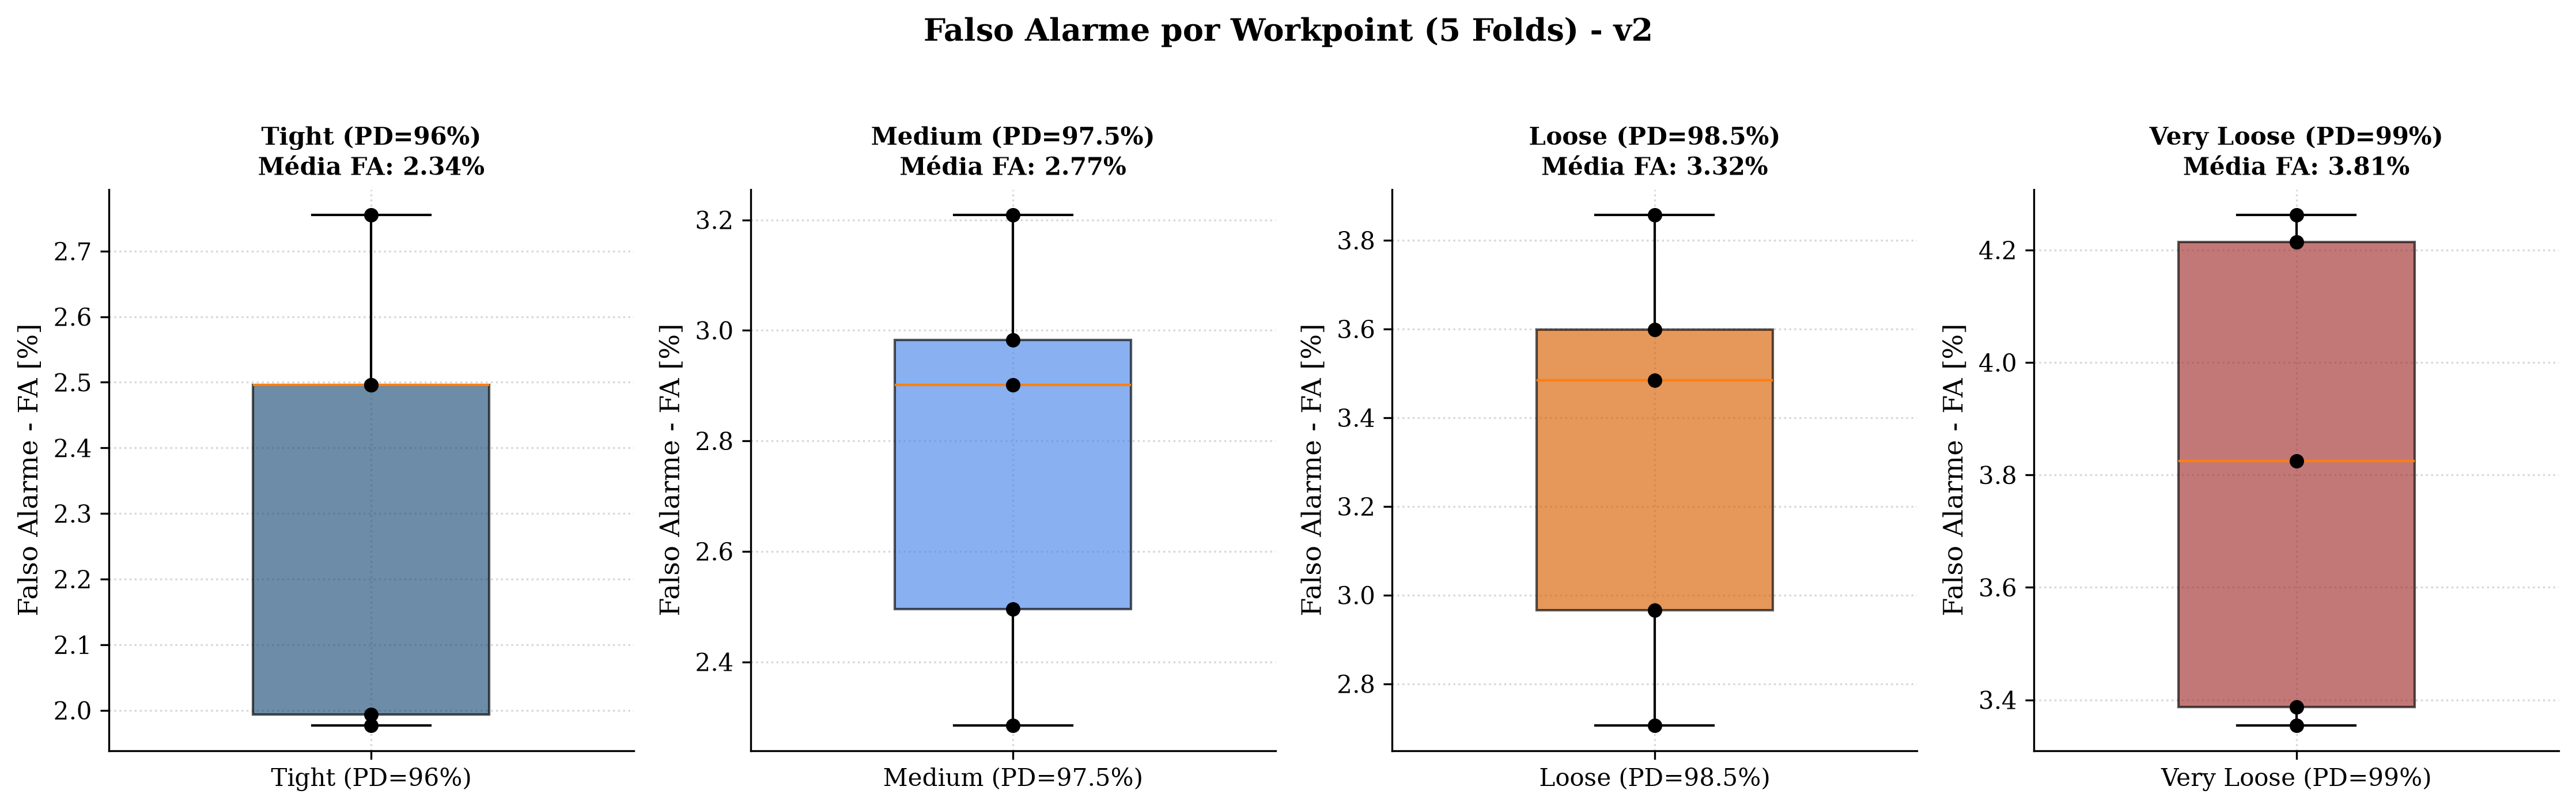

In [5]:
plots_dir = os.path.join(base_dir, "plots")
plot_files = [
    f"rings_profile_v{VERSION}.png",
    "sensitivity_validation.png",
    "kkt_primal_dual_evolution.png",
    "kkt_primal_dual_evolution_measured.png",
    "pareto_sp_vs_lut.png",
    "vu13p_resource_utilization.png",
    "learning_curves.png",
    "roc_best_model.png",
    "roc_duel_fp32_vs_kkt.png",
    "roc_cv_envelope.png",
    "output_scores_hist.png",
    "confusion_matrix_knee.png",
    "cv_boxplots.png",
    "fa_per_fold_workpoints.png",
]

for pfile in plot_files:
    full_p = os.path.join(plots_dir, pfile)
    if os.path.exists(full_p):
        print(f"\n--- {pfile} ---")
        display(Image(filename=full_p, width=900))
